In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent

if not (PROJECT_ROOT / "datasets").exists():
    PROJECT_ROOT = Path.cwd().parent.parent

DATASET_DIR = PROJECT_ROOT / "datasets"

sns.set_theme(style="whitegrid")

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATASET_DIR)

Project root: /home/mohamed-amine/Downloads/EVA_ethereum/ml
Dataset directory: /home/mohamed-amine/Downloads/EVA_ethereum/ml/datasets


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

In [7]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Find the ML project root
current = Path.cwd().resolve()
candidates = [current, *current.parents]

if (current / "ml" / "src" / "__init__.py").exists():
    candidates.insert(0, current / "ml")

ML_ROOT = next(
    (p for p in candidates if (p / "src" / "__init__.py").exists()),
    None
)

if ML_ROOT is None:
    raise RuntimeError("Cannot find ml project root. Check your notebook location.")

REPO_ROOT = ML_ROOT.parent

sys.path.insert(0, str(ML_ROOT))

DATASET_DIR = REPO_ROOT / "datasets"
REPORT_DIR = ML_ROOT / "reports" / "eda"
FIGURES_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Repository:", REPO_ROOT)
print("ML project:", ML_ROOT)
print("Dataset directory:", DATASET_DIR)

Repository: /home/mohamed-amine/Downloads/EVA_ethereum
ML project: /home/mohamed-amine/Downloads/EVA_ethereum/ml
Dataset directory: /home/mohamed-amine/Downloads/EVA_ethereum/datasets


In [8]:
from src.ingestion.jsonl_loader import load_all_datasets

df = load_all_datasets()

print("\nDataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

eclipse.jsonl: 540 observations
normal.jsonl: 540 observations
rpc_flooding.jsonl: 540 observations

Total observations: 1620

Dataset shape: (1620, 8)

Columns:
['timestamp', 'node_id', 'scenario', 'collection_interval', 'component', 'metrics', 'system', '_source_file']


,timestamp,node_id,scenario,collection_interval,component,metrics,system,_source_file
0,2026-11-18T14:59:41Z,node-01,ECLIPSE,5,geth,"{'peer_count': 3, 'admin_peer_count': 1, 'peer...","{'cpu_usage_percent': 5.233618421052631, 'memo...",eclipse.jsonl
1,2026-11-18T14:59:41Z,node-01,ECLIPSE,5,beacon,"{'peer_count': 4, 'connecting_peers': 0, 'inbo...","{'cpu_usage_percent': 0.8119672131147541, 'mem...",eclipse.jsonl
2,2026-11-18T14:59:41Z,node-01,ECLIPSE,5,validator,"{'attestations_total': 28, 'attestation_failur...","{'cpu_usage_percent': 0.0050163934426229505, '...",eclipse.jsonl
3,2026-11-18T14:59:41Z,node-02,ECLIPSE,5,geth,"{'peer_count': 1, 'admin_peer_count': 0, 'peer...","{'cpu_usage_percent': 1.6894078398665555, 'mem...",eclipse.jsonl
4,2026-11-18T14:59:41Z,node-02,ECLIPSE,5,beacon,"{'peer_count': 4, 'connecting_peers': 0, 'inbo...","{'cpu_usage_percent': 0.10922693266832918, 'me...",eclipse.jsonl


In [9]:
print("Columns:", df.columns.tolist())

print("\nFirst observation:")
display(df.iloc[0])

print("\nMetrics example:")
print(df.iloc[0]["metrics"])

print("\nSystem example:")
print(df.iloc[0]["system"])

Columns: ['timestamp', 'node_id', 'scenario', 'collection_interval', 'component', 'metrics', 'system', '_source_file']

First observation:


timestamp                                           2026-11-18T14:59:41Z
node_id                                                          node-01
scenario                                                         ECLIPSE
collection_interval                                                    5
component                                                           geth
metrics                {'peer_count': 3, 'admin_peer_count': 1, 'peer...
system                 {'cpu_usage_percent': 5.233618421052631, 'memo...
_source_file                                               eclipse.jsonl
Name: 0, dtype: object


Metrics example:
{'peer_count': 3, 'admin_peer_count': 1, 'peer_details_available': True, 'new_peers': None, 'disconnected_peers': None, 'peer_churn_count': None, 'network_listening': True, 'txpool_pending': 0, 'txpool_queued': 0, 'rpc_available': True, 'rpc_latency_ms': 18.811115, 'rpc_requests_total': 121636, 'rpc_failed_requests_total': 0, 'rpc_requests_per_sec': None, 'block_number': 926, 'is_synced': True, 'latest_block_age_secs': 2, 'block_execution_ms': None, 'block_tx_count': 0}

System example:
{'cpu_usage_percent': 5.233618421052631, 'memory_used_mb': 133, 'memory_total_mb': 31793, 'network_rx_bytes_total': 126202375, 'network_tx_bytes_total': 297079513, 'network_rx_bytes_per_sec': None, 'network_tx_bytes_per_sec': None, 'tcp_established_connections': 8}


In [10]:
for component in sorted(df["component"].dropna().unique()):

    sample = df[df["component"] == component].iloc[0]

    print(f"\n{'=' * 60}")
    print("COMPONENT:", component)
    print("=" * 60)

    print("\nMetrics keys:")
    print(list(sample["metrics"].keys()) if isinstance(sample["metrics"], dict) else sample["metrics"])

    print("\nSystem keys:")
    print(list(sample["system"].keys()) if isinstance(sample["system"], dict) else sample["system"])


COMPONENT: beacon

Metrics keys:
['peer_count', 'connecting_peers', 'inbound_peers', 'outbound_peers', 'new_peers', 'disconnected_peers', 'peer_churn_count', 'unique_peer_ips', 'unique_peer_clients', 'top_client_ratio', 'finalized_epoch', 'justified_epoch', 'finality_distance_epochs', 'reorgs_total', 'head_slot', 'sync_distance', 'is_syncing', 'is_optimistic', 'el_offline', 'block_propagation_delay_ms', 'attestation_inclusion_distance']

System keys:
['cpu_usage_percent', 'memory_used_mb', 'memory_total_mb', 'network_rx_bytes_total', 'network_tx_bytes_total', 'network_rx_bytes_per_sec', 'network_tx_bytes_per_sec', 'tcp_established_connections']

COMPONENT: geth

Metrics keys:
['peer_count', 'admin_peer_count', 'peer_details_available', 'new_peers', 'disconnected_peers', 'peer_churn_count', 'network_listening', 'txpool_pending', 'txpool_queued', 'rpc_available', 'rpc_latency_ms', 'rpc_requests_total', 'rpc_failed_requests_total', 'rpc_requests_per_sec', 'block_number', 'is_synced', 'la

In [11]:
print("DataFrame data types:")
display(df.dtypes.to_frame("dtype"))

print("\nDataFrame information:")
df.info()

DataFrame data types:


,dtype
timestamp,str
node_id,str
scenario,str
collection_interval,int64
component,str
metrics,object
system,object
_source_file,str



DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   timestamp            1620 non-null   str   
 1   node_id              1620 non-null   str   
 2   scenario             1620 non-null   str   
 3   collection_interval  1620 non-null   int64 
 4   component            1620 non-null   str   
 5   metrics              1620 non-null   object
 6   system               1620 non-null   object
 7   _source_file         1620 non-null   str   
dtypes: int64(1), object(2), str(5)
memory usage: 190.0+ KB


In [12]:
flat_df = pd.json_normalize(
    df.to_dict(orient="records"),
    sep="."
)

print("Original shape:", df.shape)
print("Flattened shape:", flat_df.shape)

print("\nFlattened columns:")
for column in flat_df.columns:
    print(column)

Original shape: (1620, 8)
Flattened shape: (1620, 64)

Flattened columns:
timestamp
node_id
scenario
collection_interval
component
_source_file
metrics.peer_count
metrics.admin_peer_count
metrics.peer_details_available
metrics.new_peers
metrics.disconnected_peers
metrics.peer_churn_count
metrics.network_listening
metrics.txpool_pending
metrics.txpool_queued
metrics.rpc_available
metrics.rpc_latency_ms
metrics.rpc_requests_total
metrics.rpc_failed_requests_total
metrics.rpc_requests_per_sec
metrics.block_number
metrics.is_synced
metrics.latest_block_age_secs
metrics.block_execution_ms
metrics.block_tx_count
system.cpu_usage_percent
system.memory_used_mb
system.memory_total_mb
system.network_rx_bytes_total
system.network_tx_bytes_total
system.network_rx_bytes_per_sec
system.network_tx_bytes_per_sec
system.tcp_established_connections
metrics.connecting_peers
metrics.inbound_peers
metrics.outbound_peers
metrics.unique_peer_ips
metrics.unique_peer_clients
metrics.top_client_ratio
metrics.fi

In [13]:
missing_count = flat_df.isnull().sum()

missing_percentage = (
    flat_df.isnull().mean() * 100
)

missing_report = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percentage": missing_percentage
})

missing_report = missing_report.sort_values(
    by="missing_percentage",
    ascending=False
)

display(missing_report)

,missing_count,missing_percentage
metrics.block_execution_ms,1620,100.0
metrics.missed_attestations_total,1620,100.0
metrics.proposal_effectiveness,1620,100.0
metrics.reorgs_total,1620,100.0
metrics.unique_peer_clients,1620,100.0
...,...,...
system.memory_total_mb,0,0.0
system.cpu_usage_percent,0,0.0
timestamp,0,0.0
scenario,0,0.0


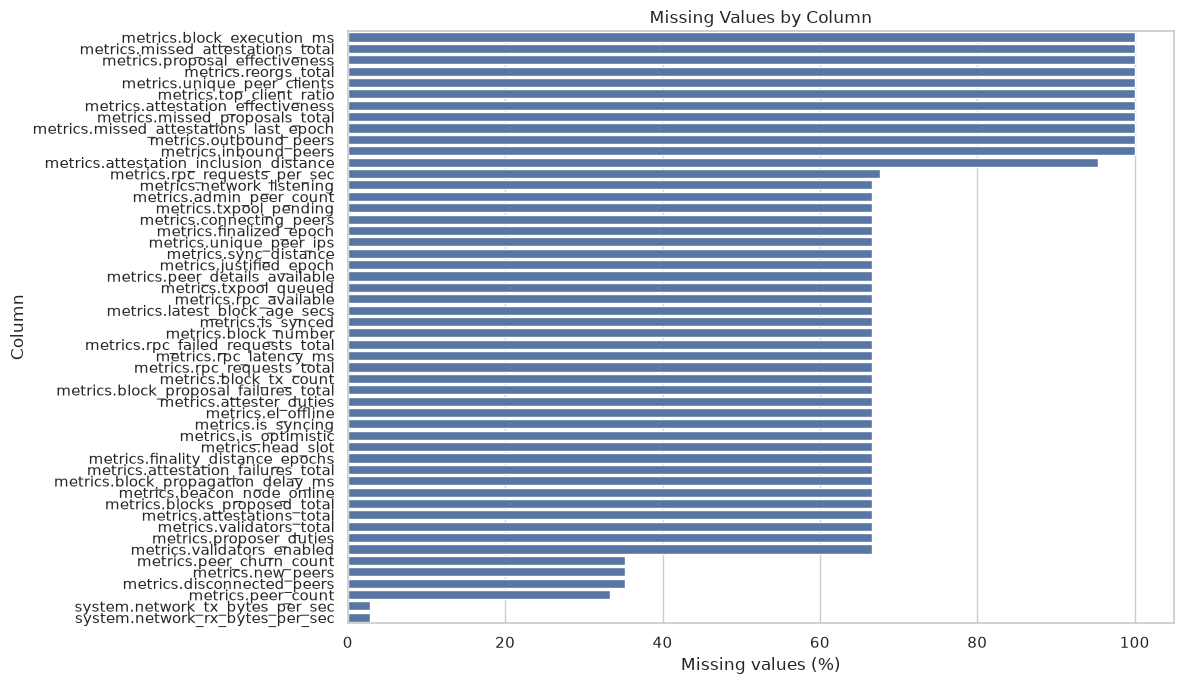

In [14]:
missing_to_plot = missing_report[
    missing_report["missing_count"] > 0
]

plt.figure(figsize=(12, 7))

sns.barplot(
    data=missing_to_plot.reset_index(),
    x="missing_percentage",
    y="index"
)

plt.title("Missing Values by Column")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_values.png", dpi=150)
plt.show()

In [15]:
exact_duplicates = flat_df.drop(
    columns=["_source_file"],
    errors="ignore"
).duplicated().sum()

print("Exact duplicate observations:", exact_duplicates)

Exact duplicate observations: 0


In [16]:
print("Scenario distribution:")
display(df["scenario"].value_counts().to_frame("observations"))

print("\nScenario percentages:")
display(
    (df["scenario"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("percentage")
)

Scenario distribution:


,observations
scenario,
ECLIPSE,540
NORMAL,540
RPC_FLOODING,540



Scenario percentages:


,percentage
scenario,
ECLIPSE,33.33
NORMAL,33.33
RPC_FLOODING,33.33


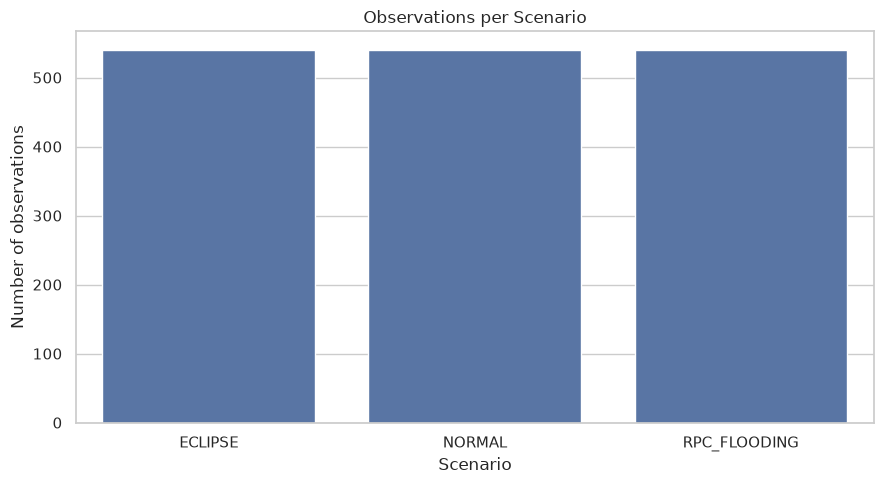

In [17]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="scenario",
    order=df["scenario"].value_counts().index
)

plt.title("Observations per Scenario")
plt.xlabel("Scenario")
plt.ylabel("Number of observations")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "scenario_distribution.png", dpi=150)
plt.show()

In [18]:
print("Observations per component:")
display(df["component"].value_counts().to_frame("observations"))

print("\nScenario vs component:")
component_scenario = pd.crosstab(
    df["scenario"],
    df["component"]
)

display(component_scenario)

Observations per component:


,observations
component,
geth,540
beacon,540
validator,540



Scenario vs component:


component,beacon,geth,validator
scenario,,,
ECLIPSE,180,180,180
NORMAL,180,180,180
RPC_FLOODING,180,180,180


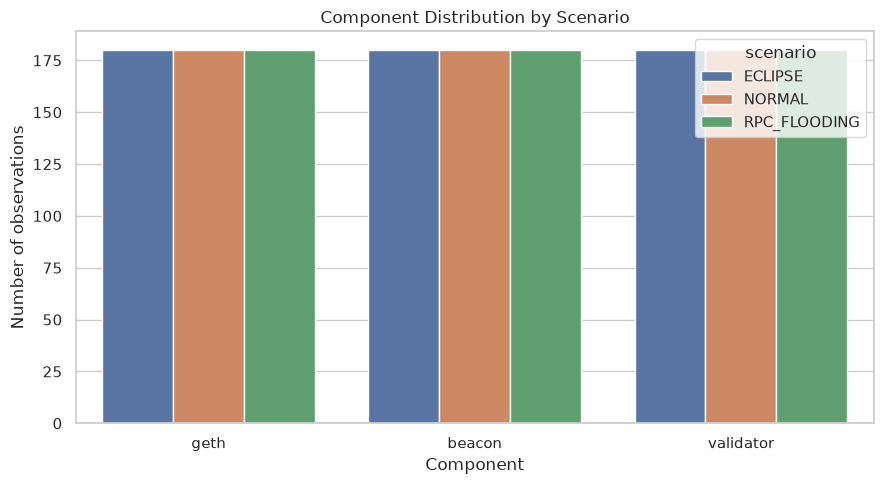

In [19]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="component",
    hue="scenario"
)

plt.title("Component Distribution by Scenario")
plt.xlabel("Component")
plt.ylabel("Number of observations")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "component_distribution.png", dpi=150)
plt.show()

In [20]:
numeric_columns = flat_df.select_dtypes(
    include=np.number
).columns.tolist()

print("Numeric columns:")
print(numeric_columns)

Numeric columns:
['collection_interval', 'metrics.peer_count', 'metrics.admin_peer_count', 'metrics.new_peers', 'metrics.disconnected_peers', 'metrics.peer_churn_count', 'metrics.txpool_pending', 'metrics.txpool_queued', 'metrics.rpc_latency_ms', 'metrics.rpc_requests_total', 'metrics.rpc_failed_requests_total', 'metrics.rpc_requests_per_sec', 'metrics.block_number', 'metrics.latest_block_age_secs', 'metrics.block_execution_ms', 'metrics.block_tx_count', 'system.cpu_usage_percent', 'system.memory_used_mb', 'system.memory_total_mb', 'system.network_rx_bytes_total', 'system.network_tx_bytes_total', 'system.network_rx_bytes_per_sec', 'system.network_tx_bytes_per_sec', 'system.tcp_established_connections', 'metrics.connecting_peers', 'metrics.inbound_peers', 'metrics.outbound_peers', 'metrics.unique_peer_ips', 'metrics.unique_peer_clients', 'metrics.top_client_ratio', 'metrics.finalized_epoch', 'metrics.justified_epoch', 'metrics.finality_distance_epochs', 'metrics.reorgs_total', 'metrics.

In [21]:
for component in sorted(flat_df["component"].dropna().unique()):

    component_data = flat_df[
        flat_df["component"] == component
    ]

    component_numeric = component_data[
        numeric_columns
    ]

    print(f"\n{'=' * 60}")
    print("COMPONENT:", component)
    print("=" * 60)

    display(component_numeric.describe().T)


COMPONENT: beacon


,count,mean,std,min,25%,50%,75%,max
collection_interval,540.0,5.000000e+00,0.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00
metrics.peer_count,540.0,4.000000e+00,0.000000e+00,4.000000e+00,4.000000e+00,4.000000e+00,4.000000e+00,4.000000e+00
metrics.admin_peer_count,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.new_peers,525.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
metrics.disconnected_peers,525.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
metrics.peer_churn_count,525.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
metrics.txpool_pending,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.txpool_queued,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.rpc_latency_ms,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.rpc_requests_total,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



COMPONENT: geth


,count,mean,std,min,25%,50%,75%,max
collection_interval,540.0,5.000000e+00,0.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00
metrics.peer_count,540.0,1.016667e+00,1.212833e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,4.000000e+00
metrics.admin_peer_count,540.0,1.001852e+00,1.214475e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,4.000000e+00
metrics.new_peers,525.0,2.095238e-02,1.678872e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00
metrics.disconnected_peers,525.0,9.523810e-03,9.721681e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
metrics.peer_churn_count,525.0,3.047619e-02,1.929699e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00
metrics.txpool_pending,540.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
metrics.txpool_queued,540.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
metrics.rpc_latency_ms,540.0,6.548705e+00,5.978135e+00,7.399010e-01,2.901828e+00,4.997868e+00,8.464798e+00,7.596647e+01
metrics.rpc_requests_total,540.0,2.203107e+05,8.621457e+05,6.096000e+03,6.529750e+03,6.944000e+03,7.701500e+03,5.888420e+06



COMPONENT: validator


,count,mean,std,min,25%,50%,75%,max
collection_interval,540.0,5.000000e+00,0.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00
metrics.peer_count,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.admin_peer_count,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.new_peers,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.disconnected_peers,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.peer_churn_count,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.txpool_pending,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.txpool_queued,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.rpc_latency_ms,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metrics.rpc_requests_total,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
for component in sorted(flat_df["component"].dropna().unique()):

    component_data = flat_df[
        flat_df["component"] == component
    ]

    component_metrics = [
        col for col in numeric_columns
        if col.startswith("metrics.") or col.startswith("system.")
        if component_data[col].notna().sum() > 0
    ]

    print(f"\n{component.upper()} — numeric metrics")

    for metric in component_metrics:

        print(f"\nMetric: {metric}")

        summary = (
            component_data
            .groupby("scenario")[metric]
            .agg(["count", "mean", "median", "std", "min", "max"])
        )

        display(summary)


BEACON — numeric metrics

Metric: metrics.peer_count


,count,mean,median,std,min,max
scenario,,,,,,
ECLIPSE,180,4.0,4.0,0.0,4.0,4.0
NORMAL,180,4.0,4.0,0.0,4.0,4.0
RPC_FLOODING,180,4.0,4.0,0.0,4.0,4.0



Metric: metrics.new_peers


,count,mean,median,std,min,max
scenario,,,,,,
ECLIPSE,175,0.0,0.0,0.0,0.0,0.0
NORMAL,175,0.0,0.0,0.0,0.0,0.0
RPC_FLOODING,175,0.0,0.0,0.0,0.0,0.0



Metric: metrics.disconnected_peers


,count,mean,median,std,min,max
scenario,,,,,,
ECLIPSE,175,0.0,0.0,0.0,0.0,0.0
NORMAL,175,0.0,0.0,0.0,0.0,0.0
RPC_FLOODING,175,0.0,0.0,0.0,0.0,0.0


... (108 outputs left out)


Metric: metrics.attester_duties


,count,mean,median,std,min,max
scenario,,,,,,
ECLIPSE,180,1.0,1.0,0.0,1.0,1.0
NORMAL,180,1.0,1.0,0.0,1.0,1.0
RPC_FLOODING,180,1.0,1.0,0.0,1.0,1.0



Metric: metrics.proposer_duties


,count,mean,median,std,min,max
scenario,,,,,,
ECLIPSE,180,6.4,6.0,1.820430,3.0,12.0
NORMAL,180,6.4,6.0,3.145627,3.0,12.0
RPC_FLOODING,180,6.4,6.0,1.500838,5.0,9.0


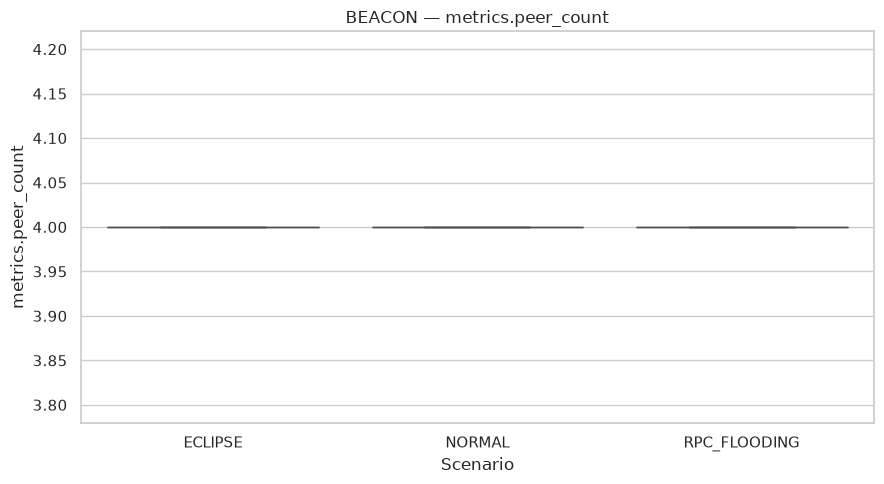

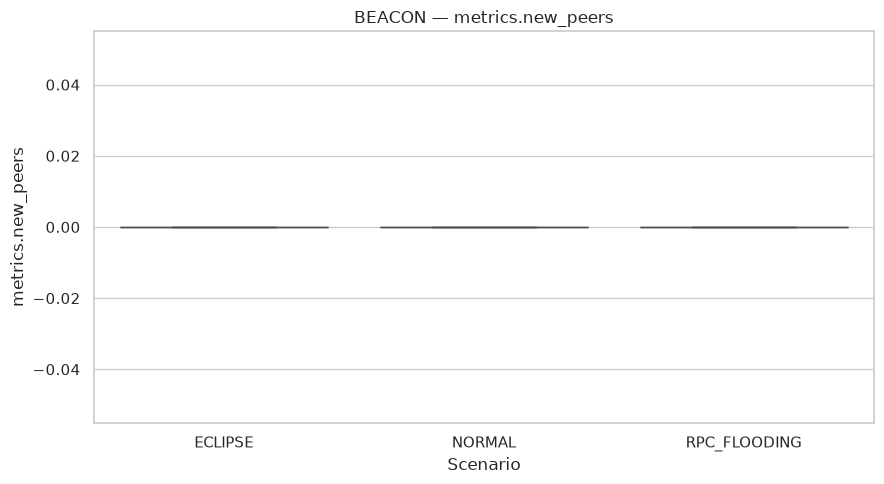

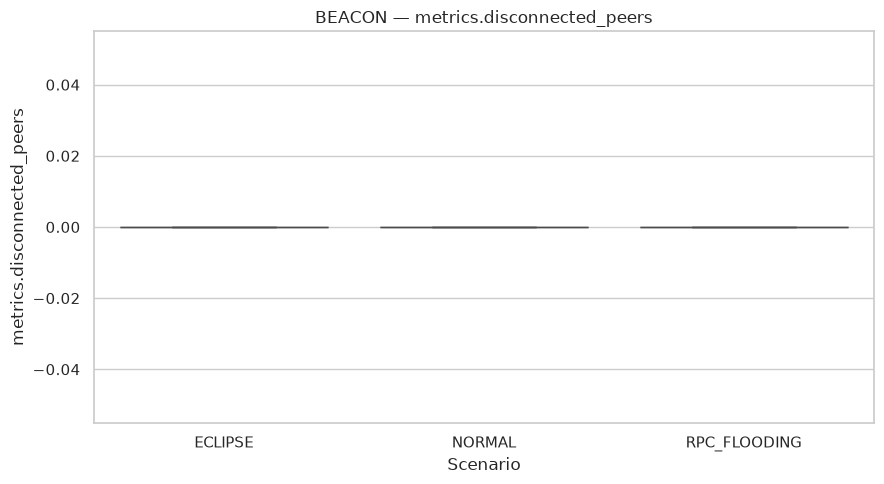

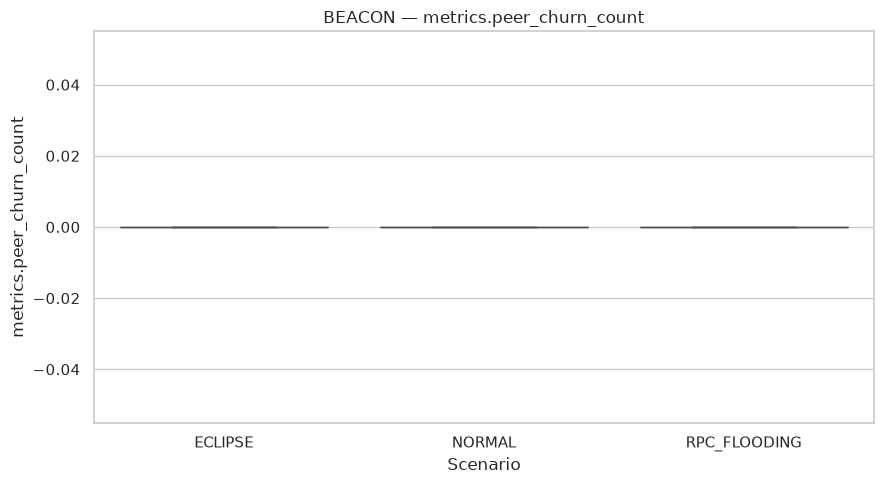

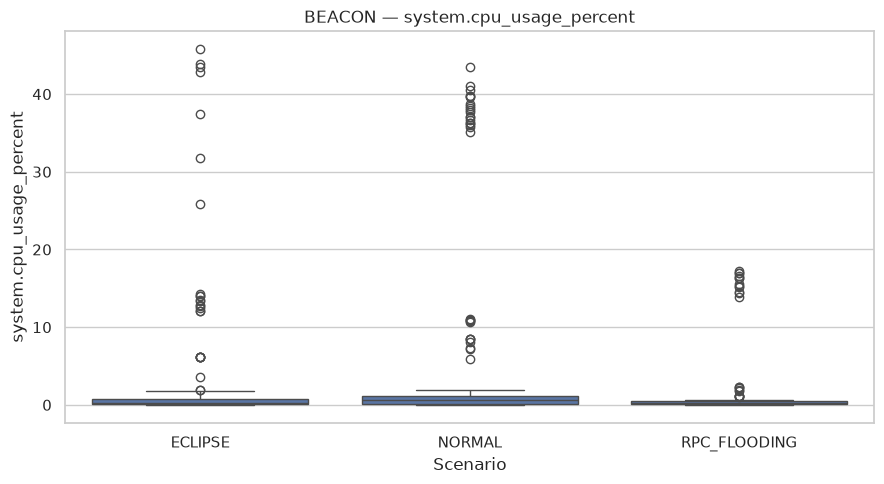

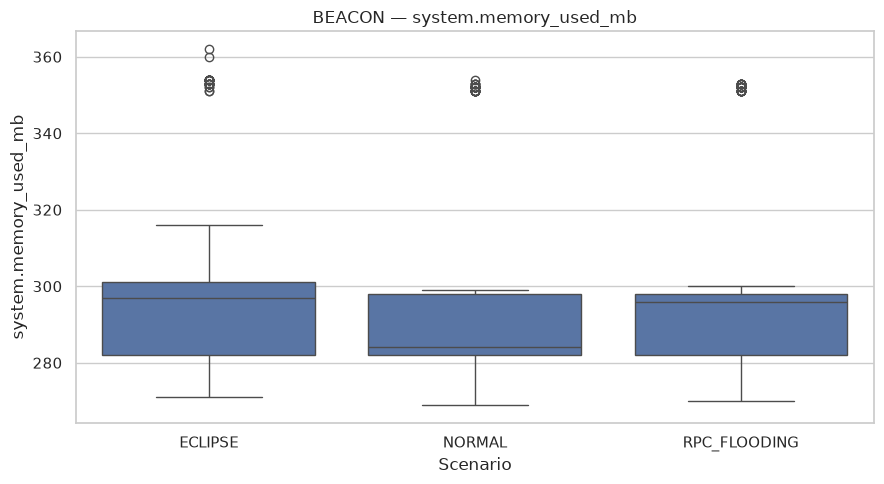

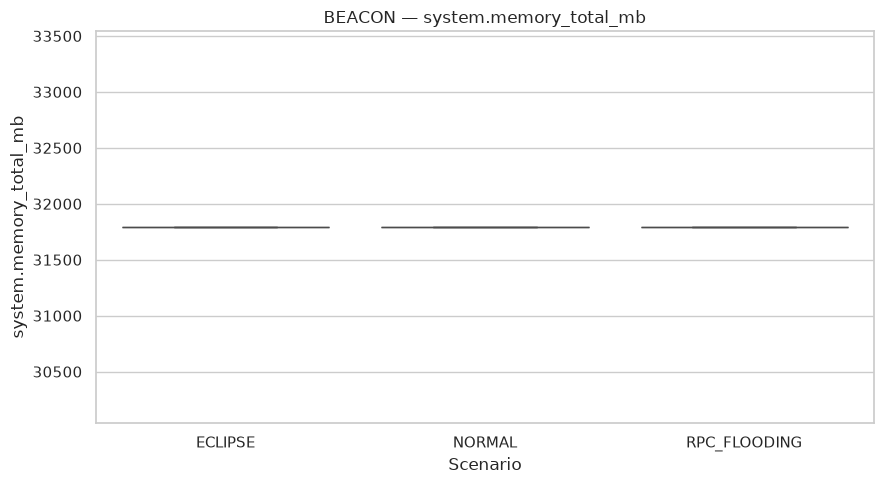

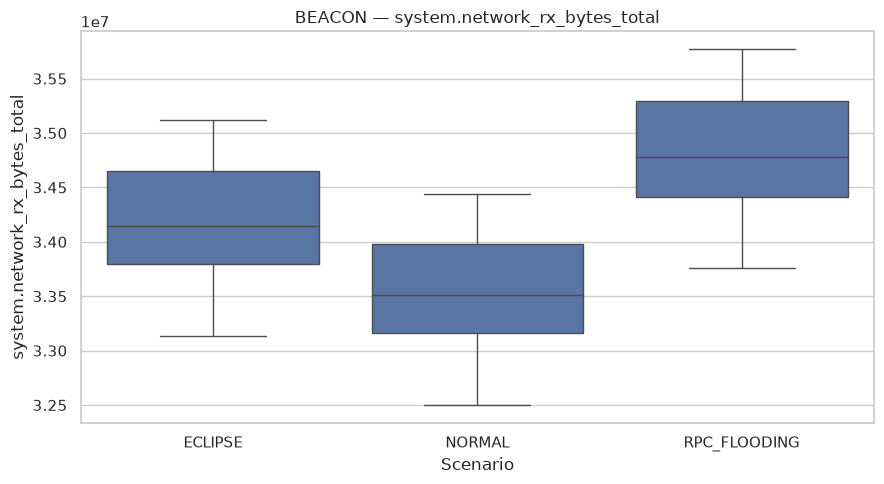

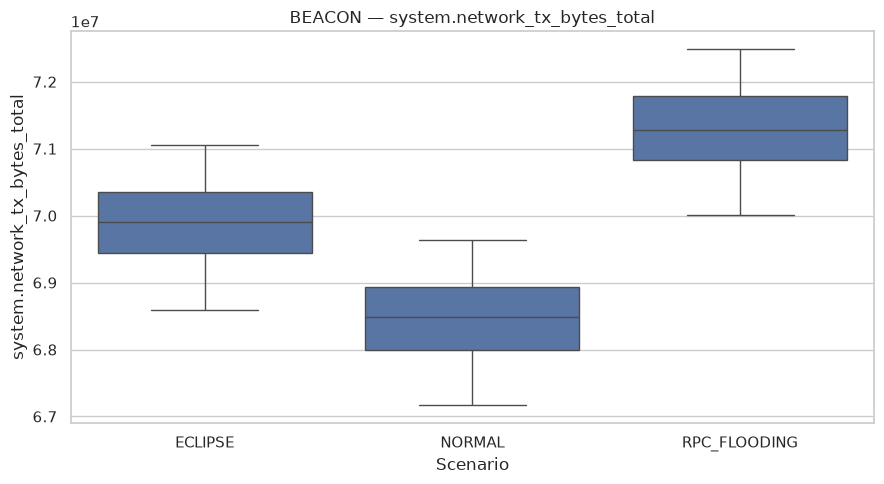

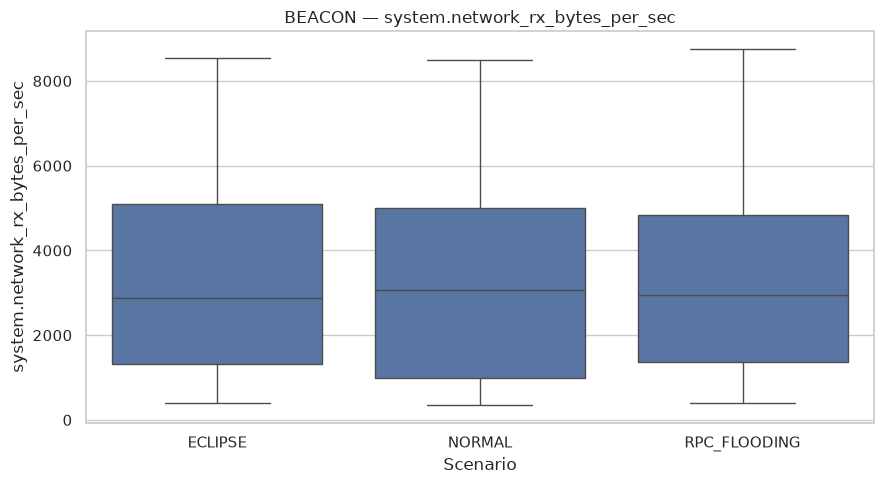

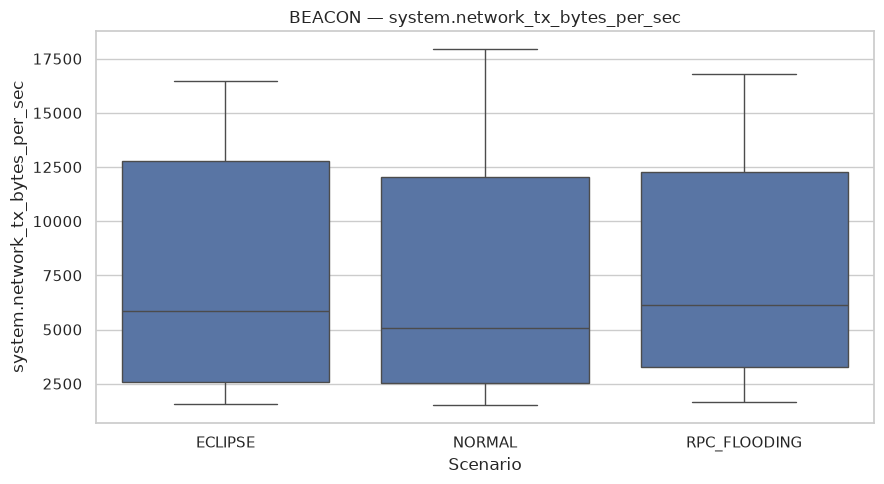

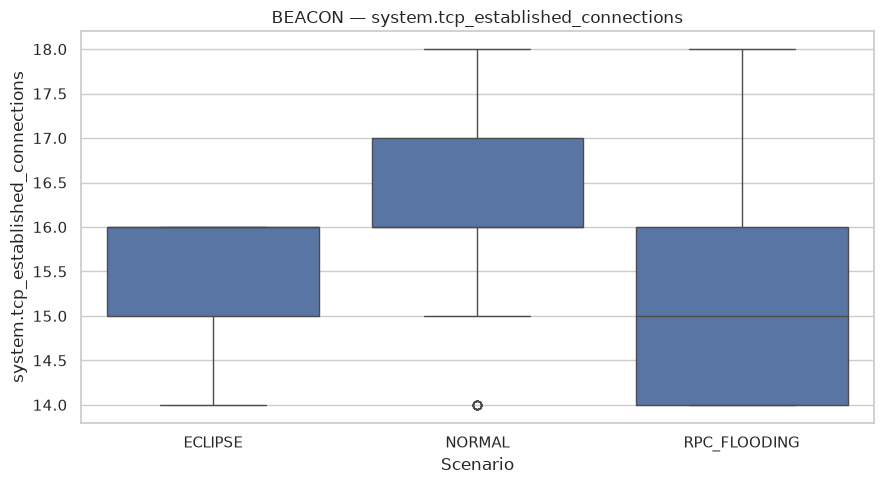

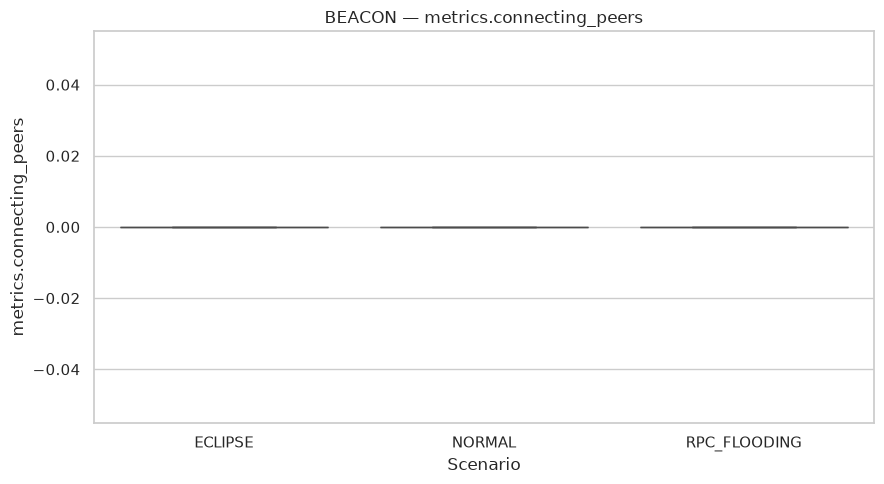

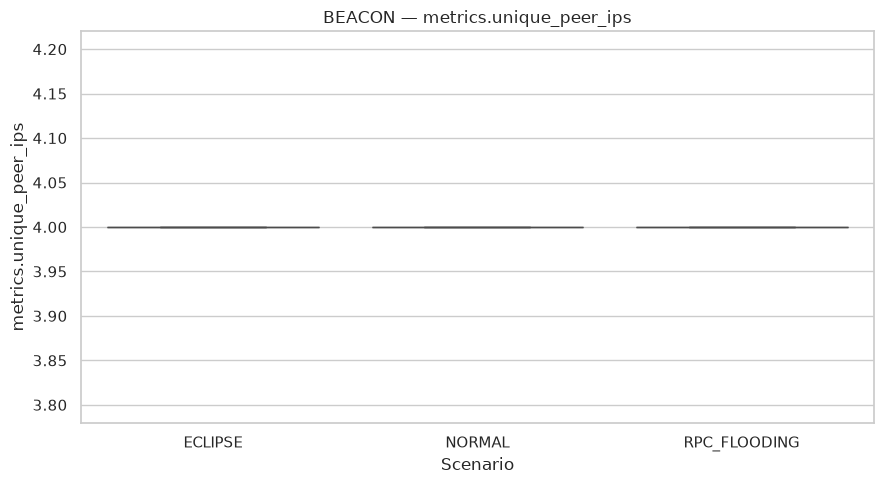

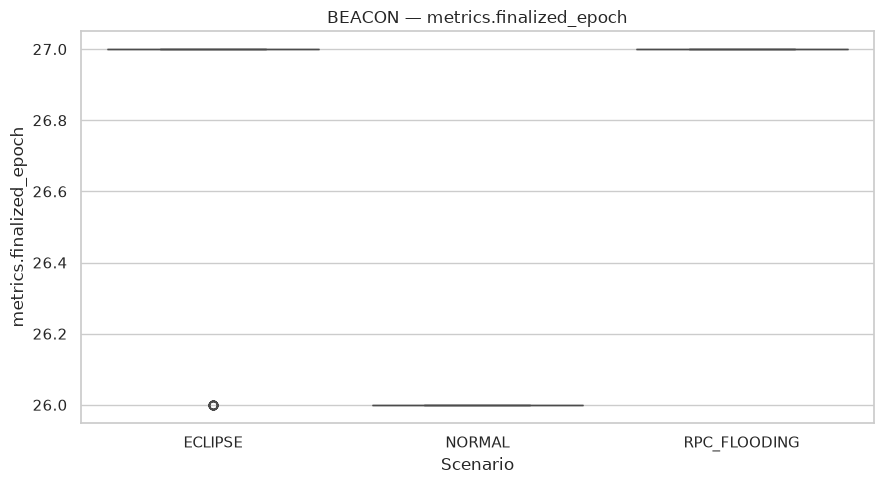

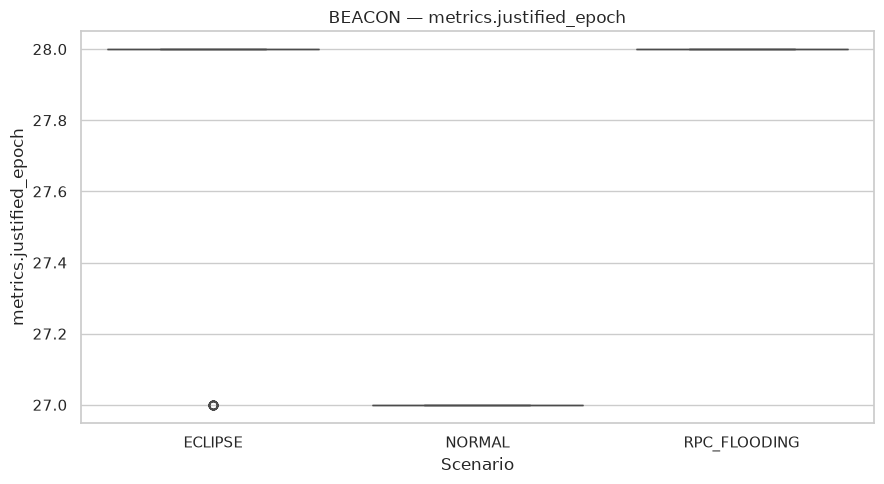

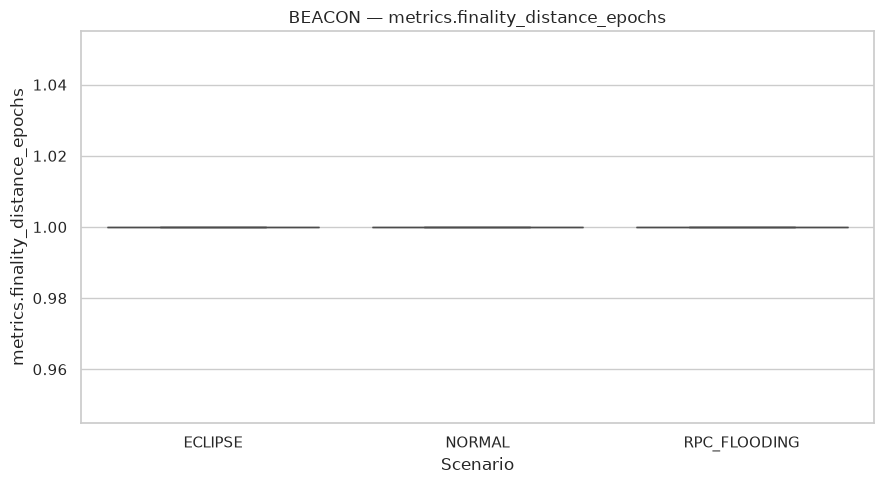

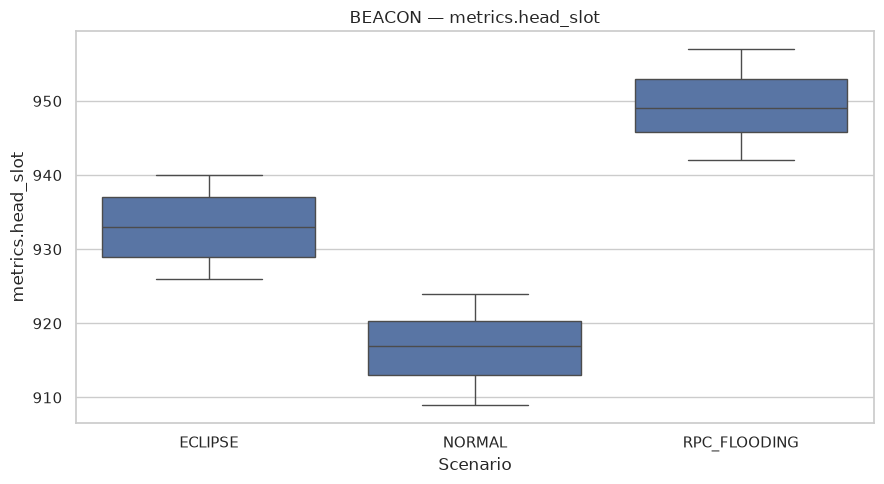

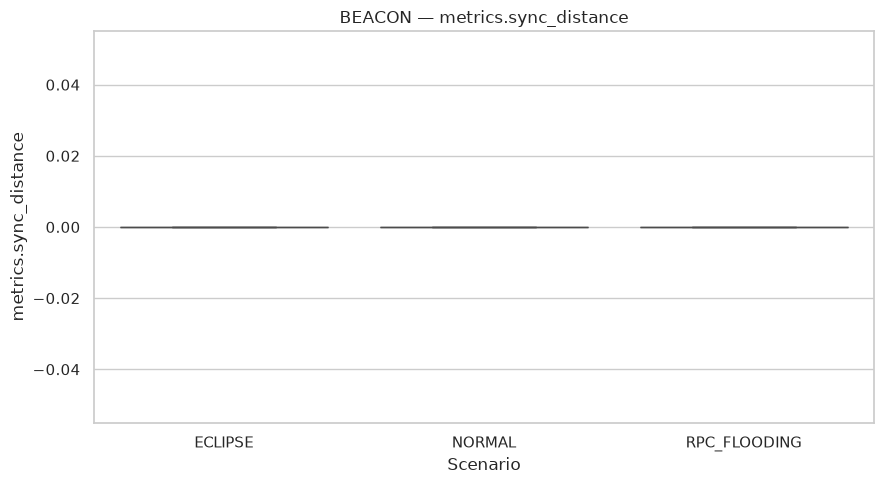

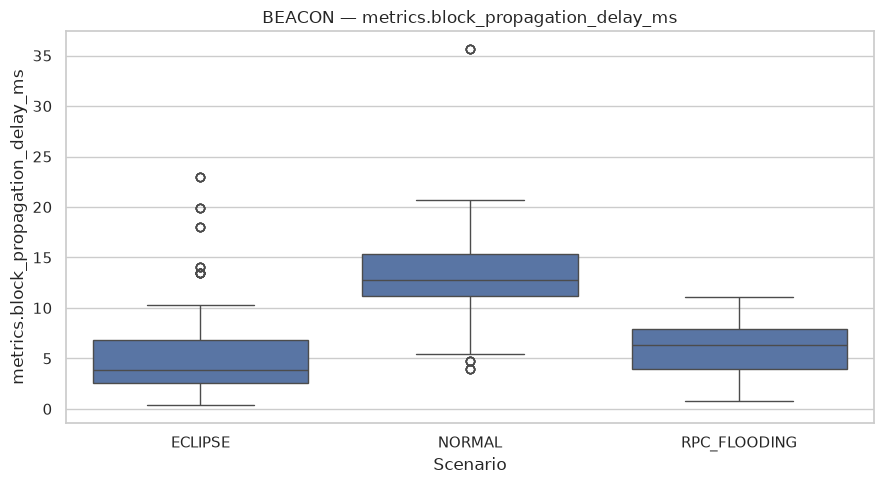

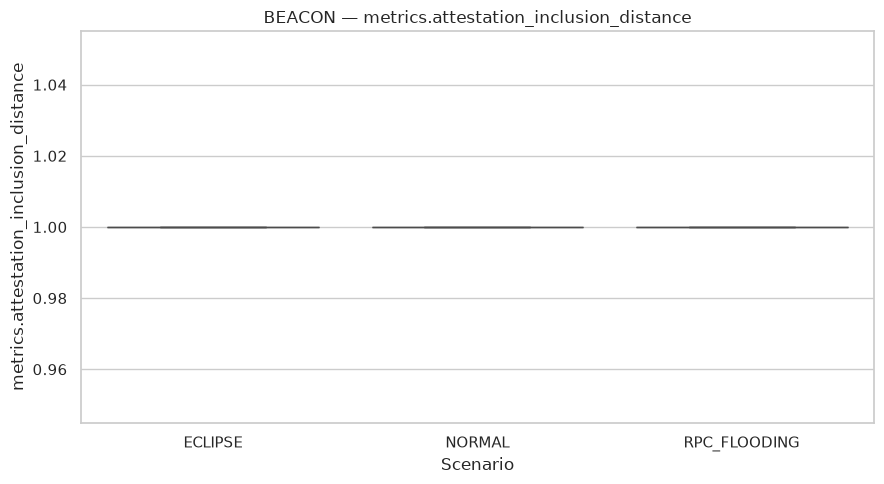

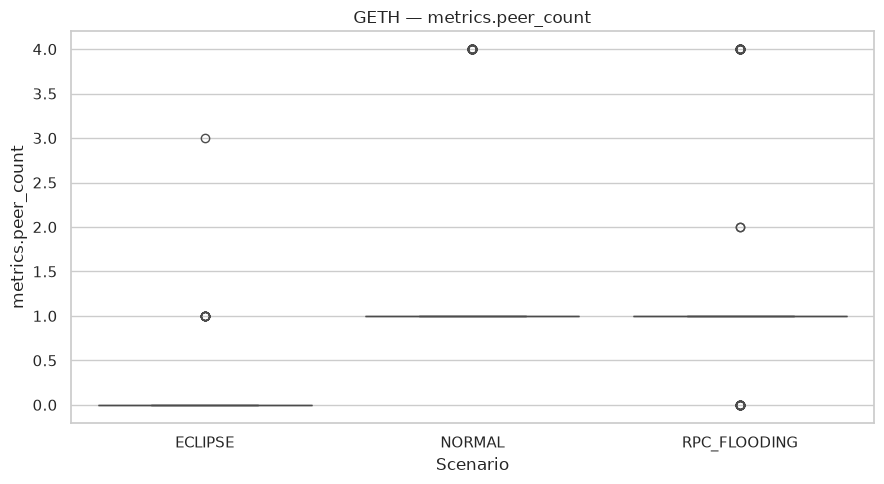

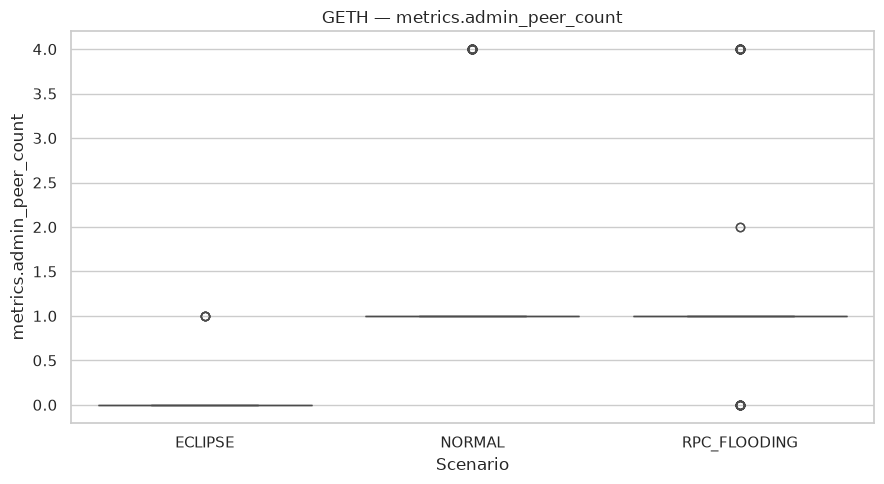

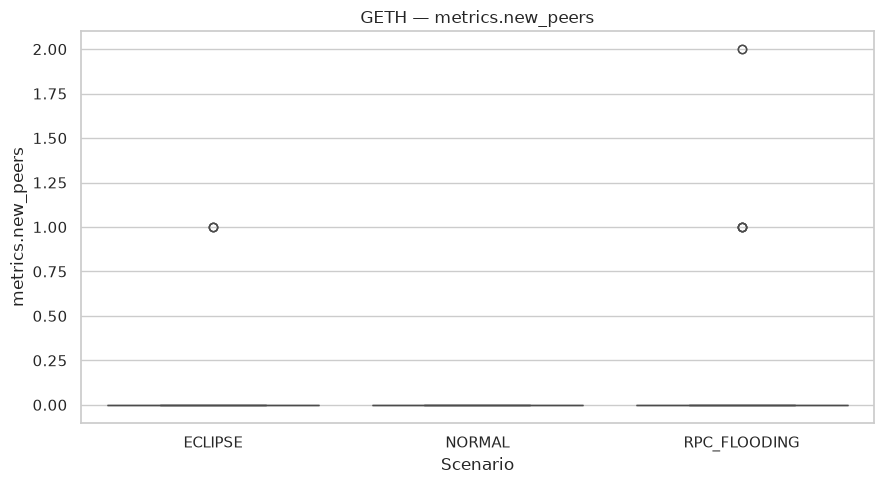

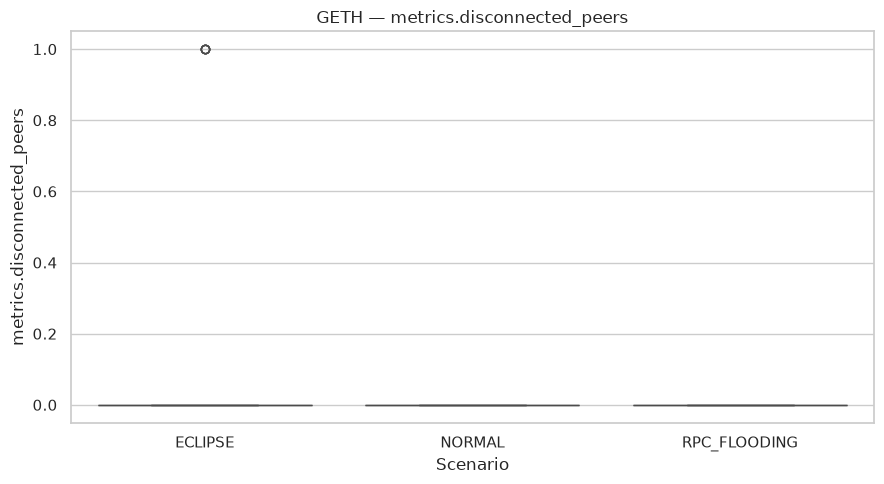

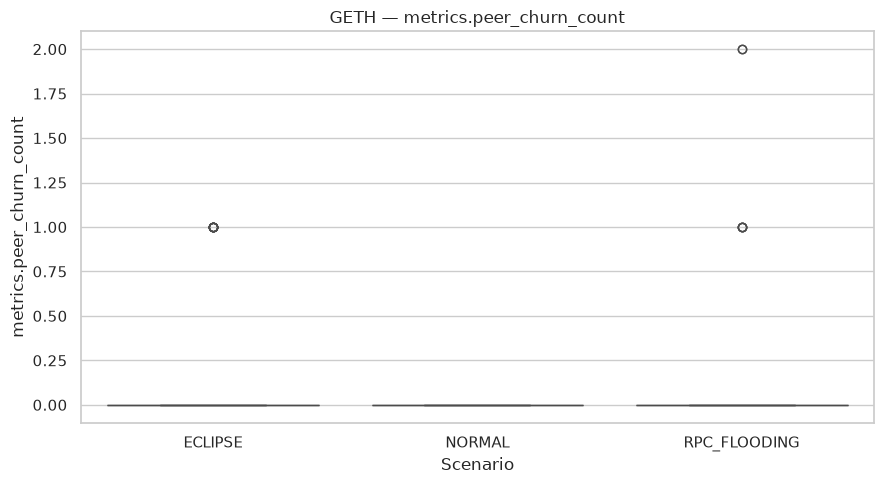

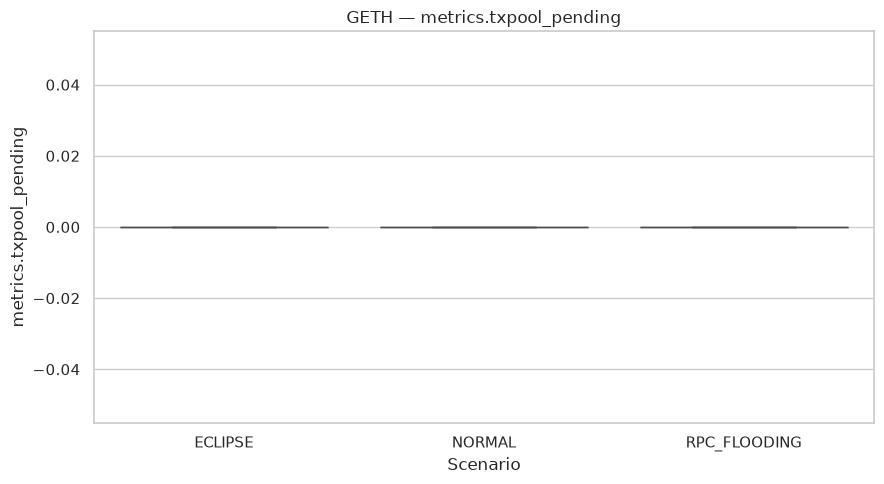

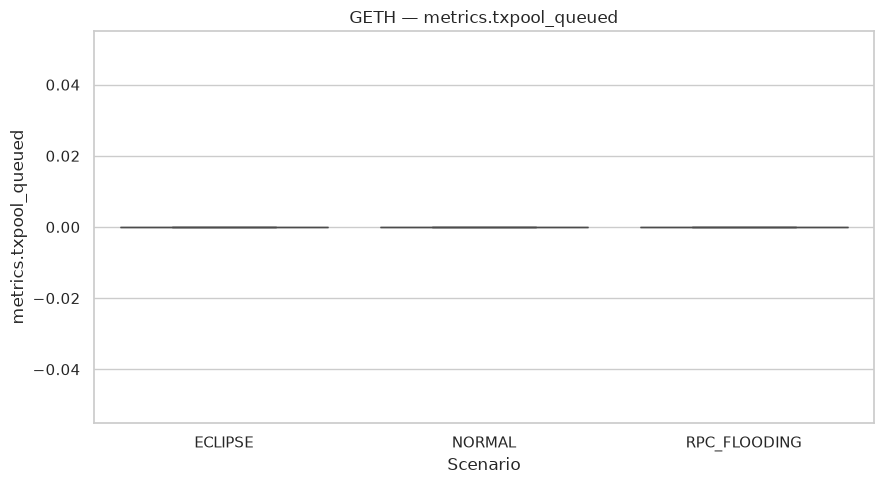

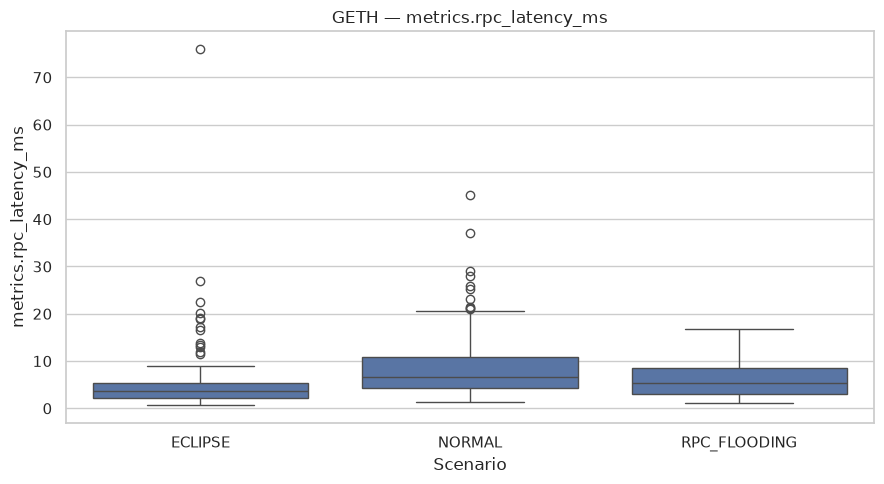

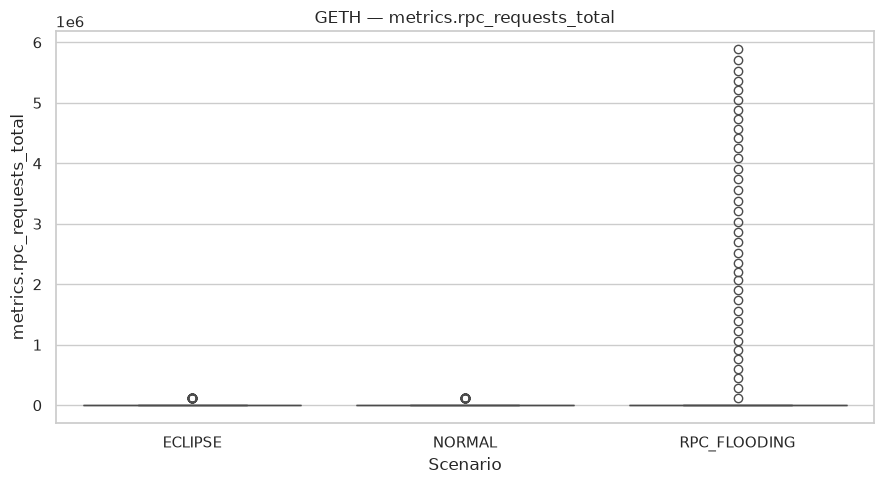

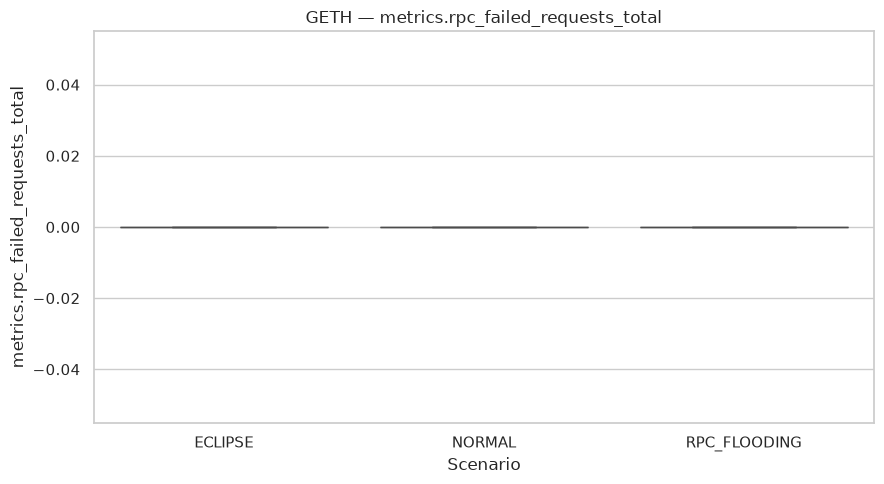

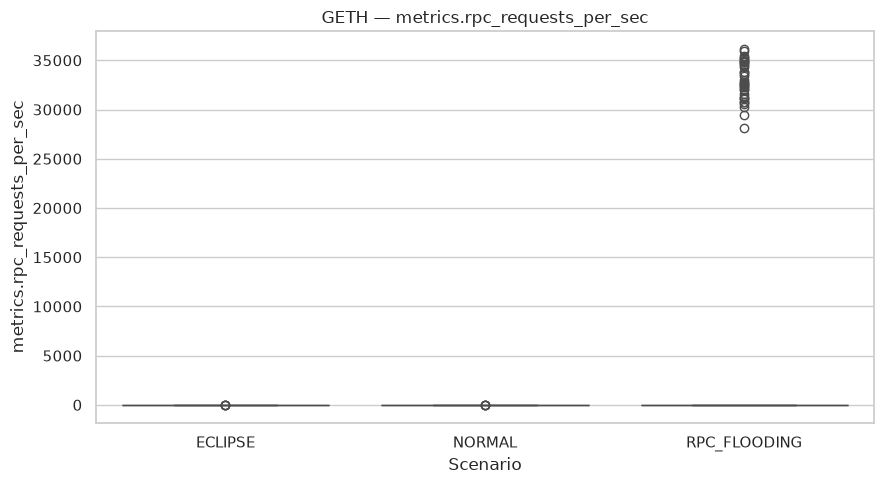

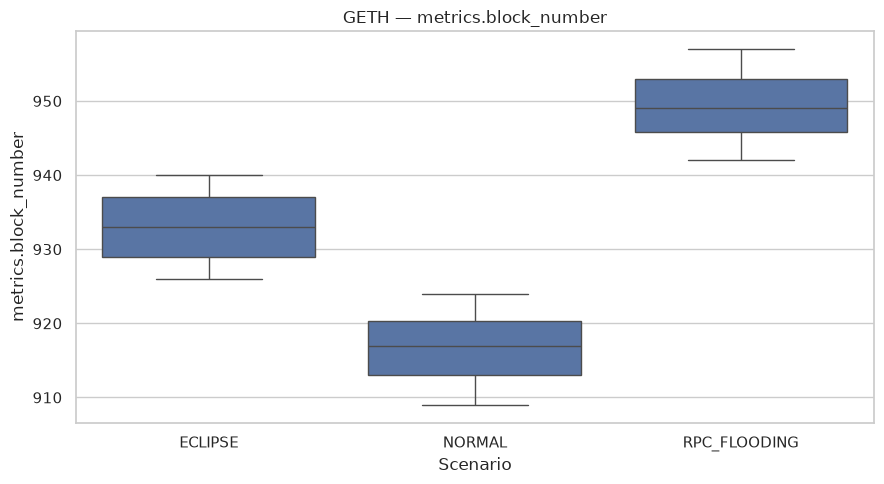

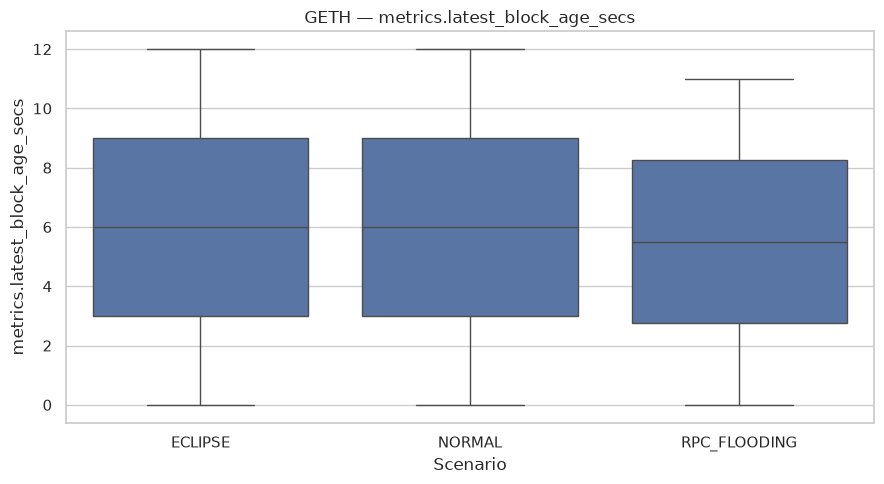

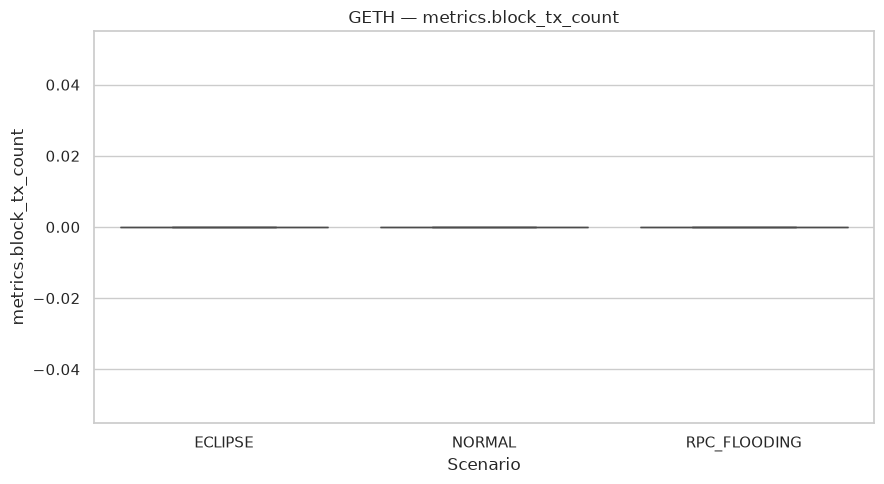

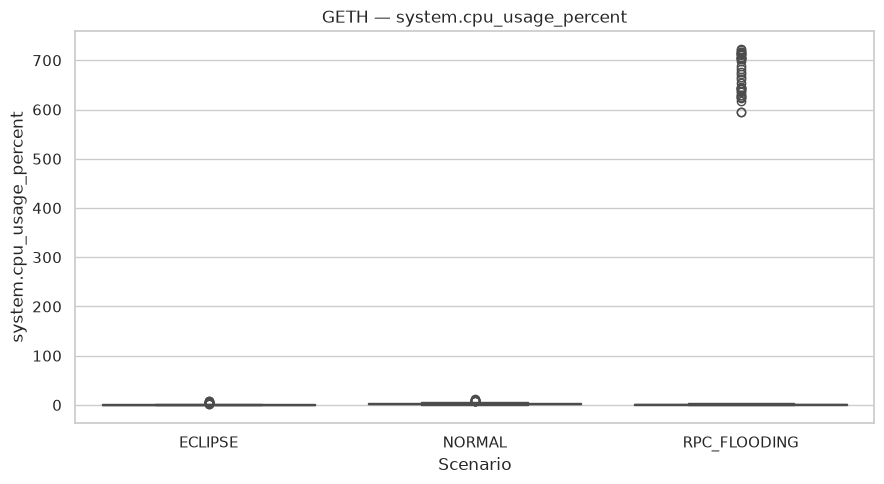

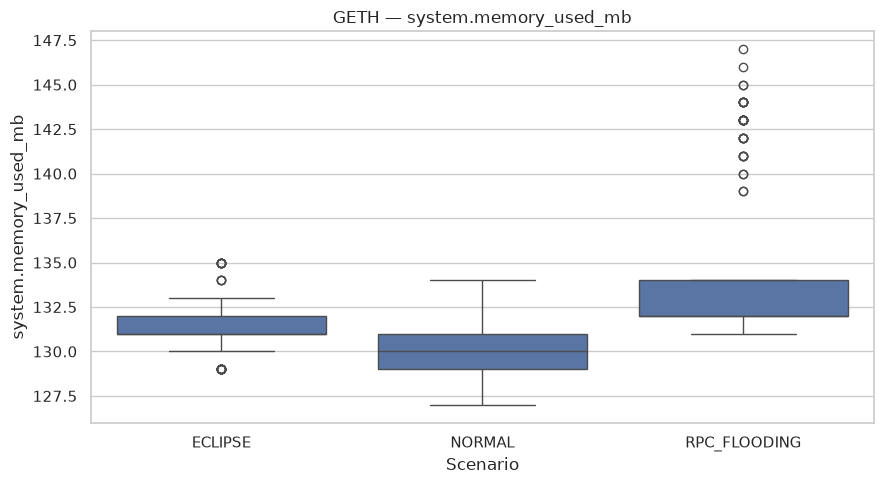

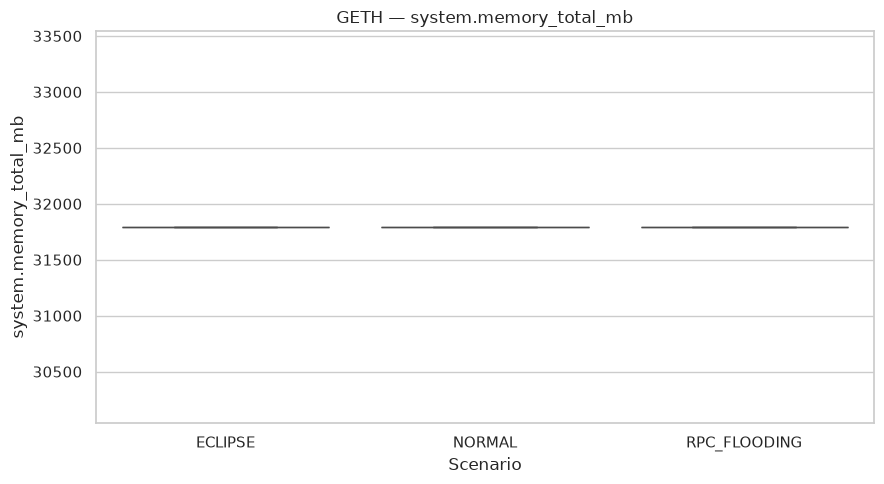

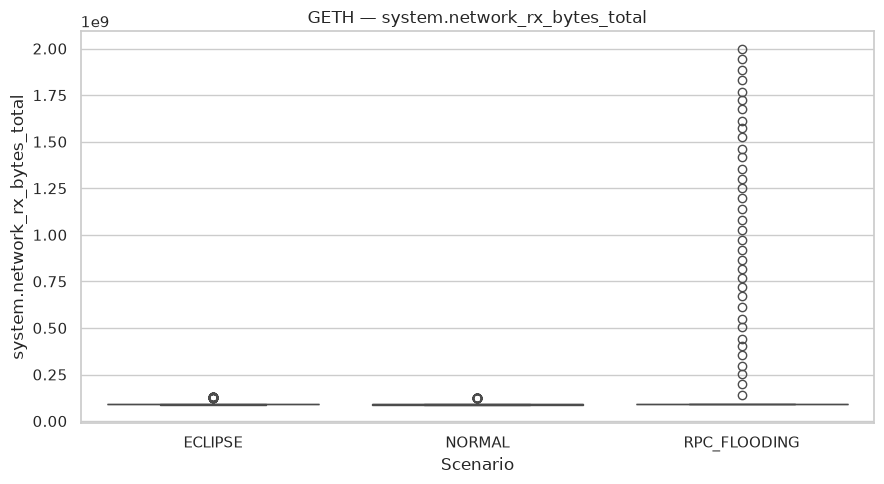

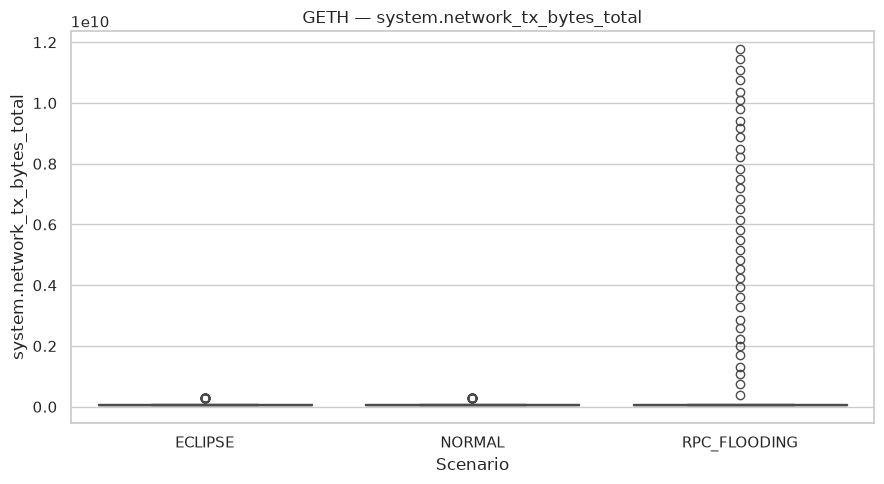

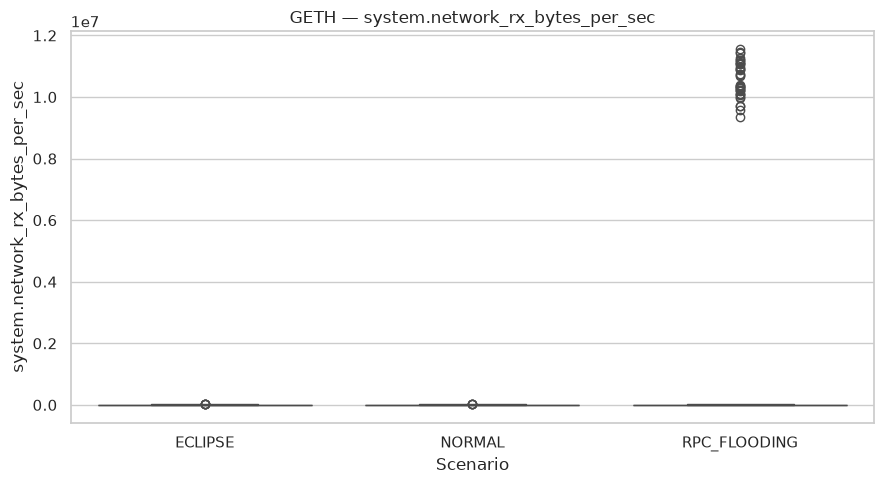

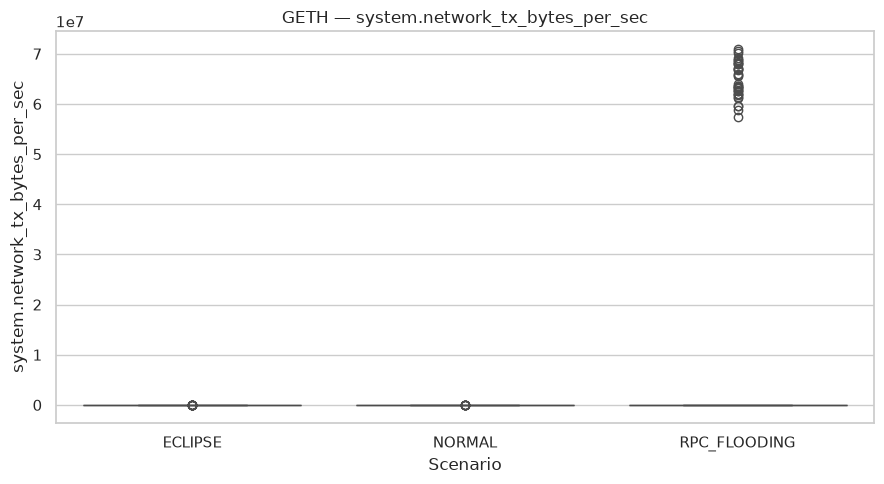

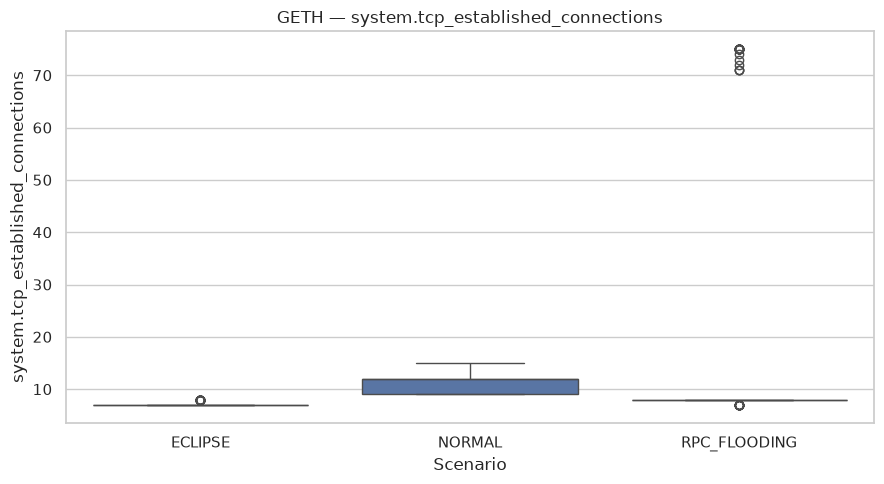

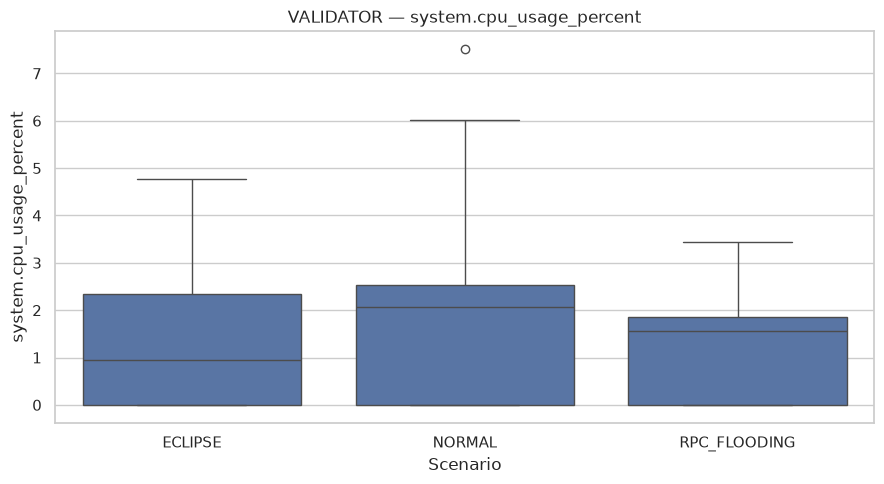

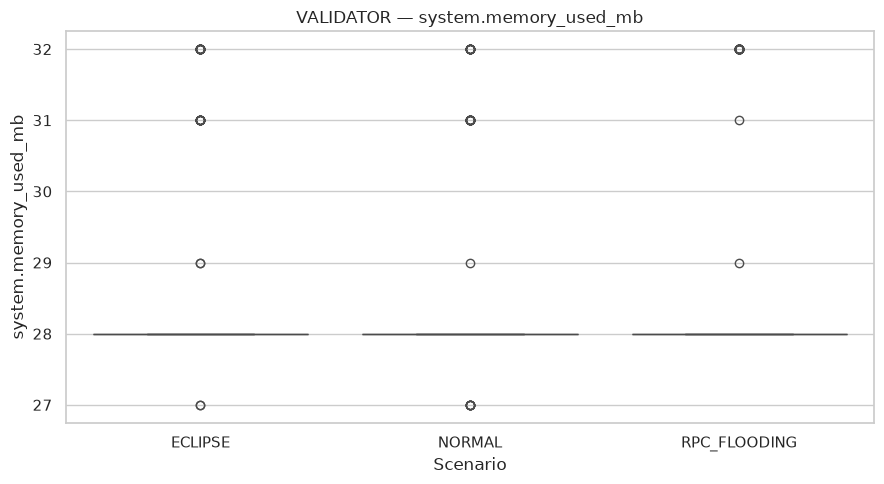

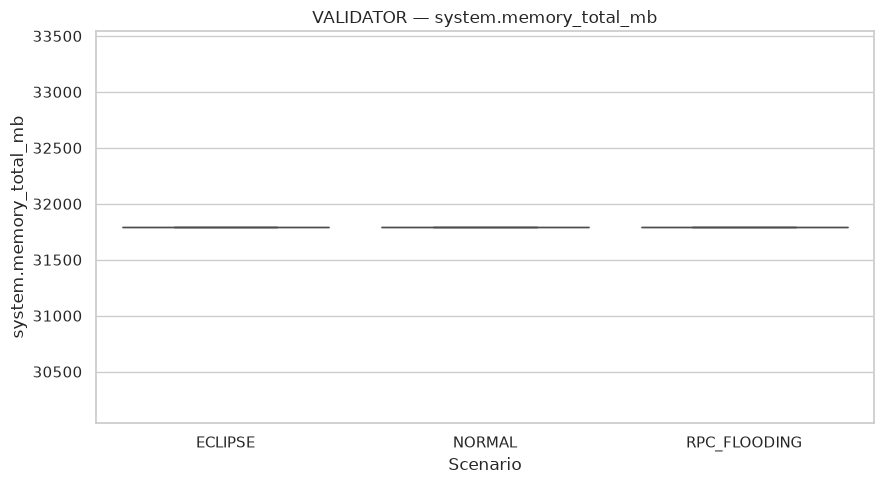

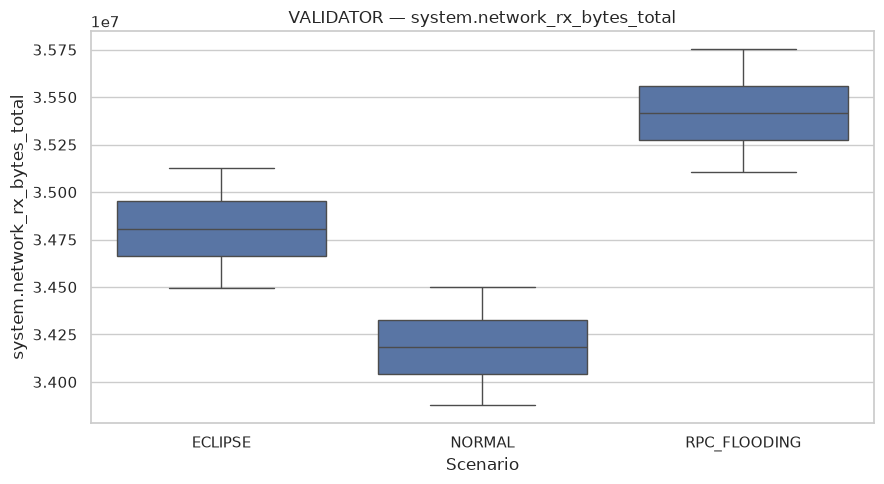

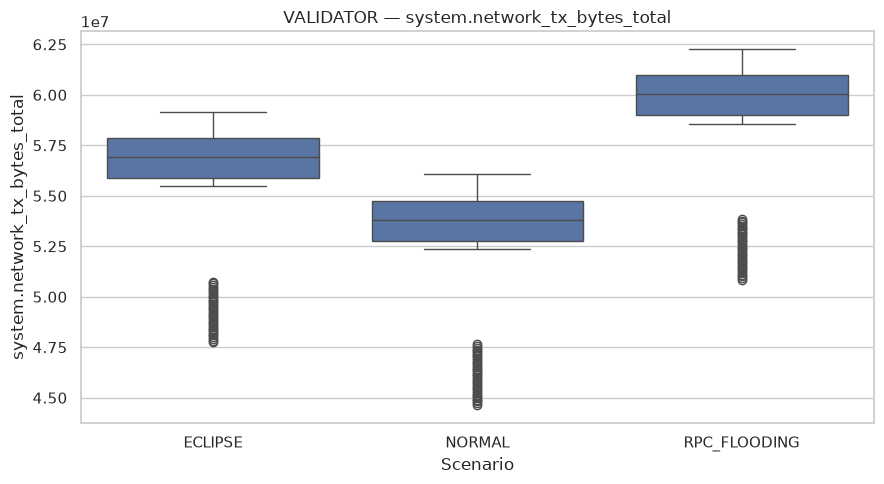

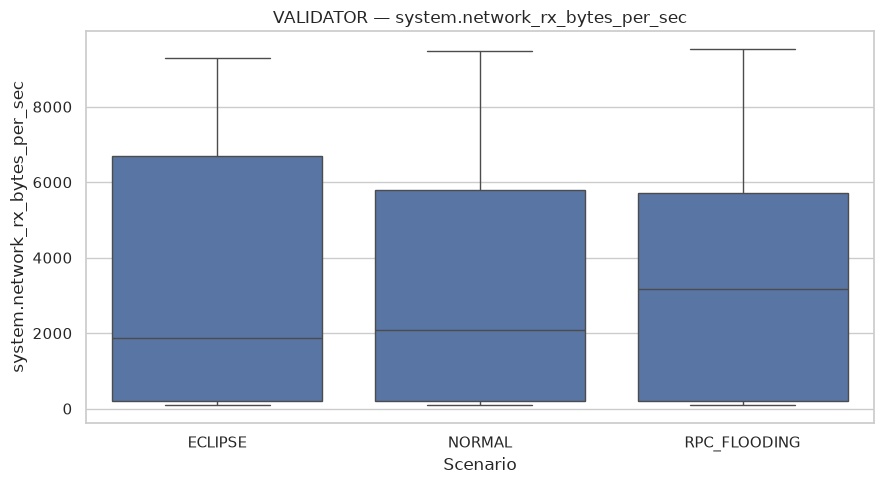

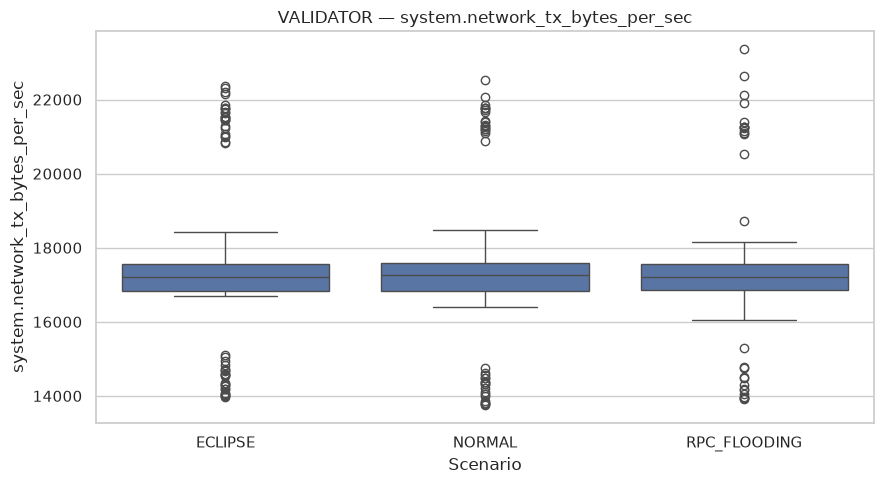

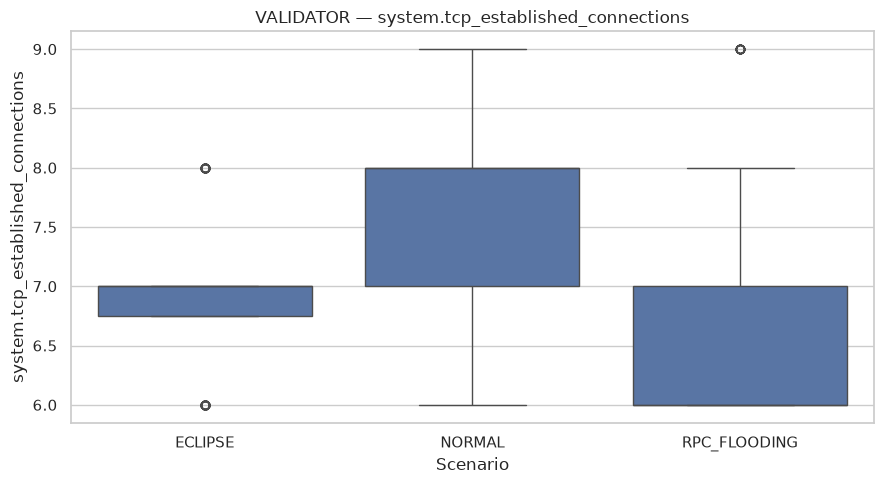

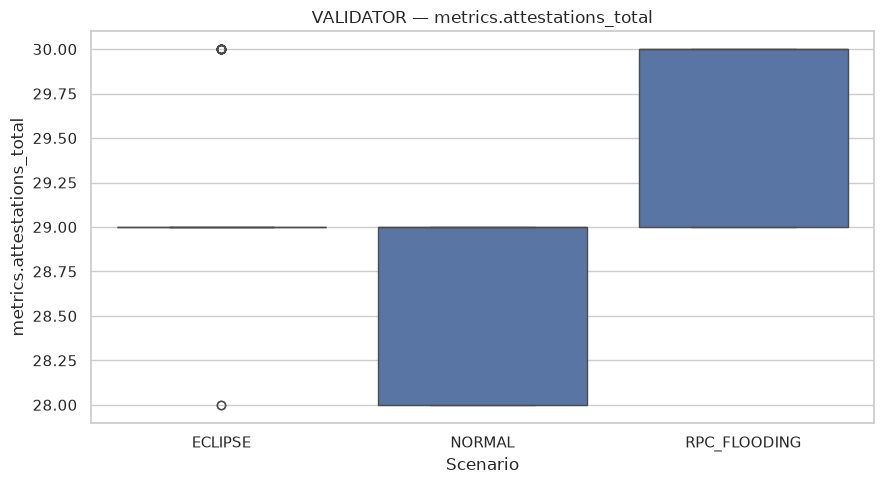

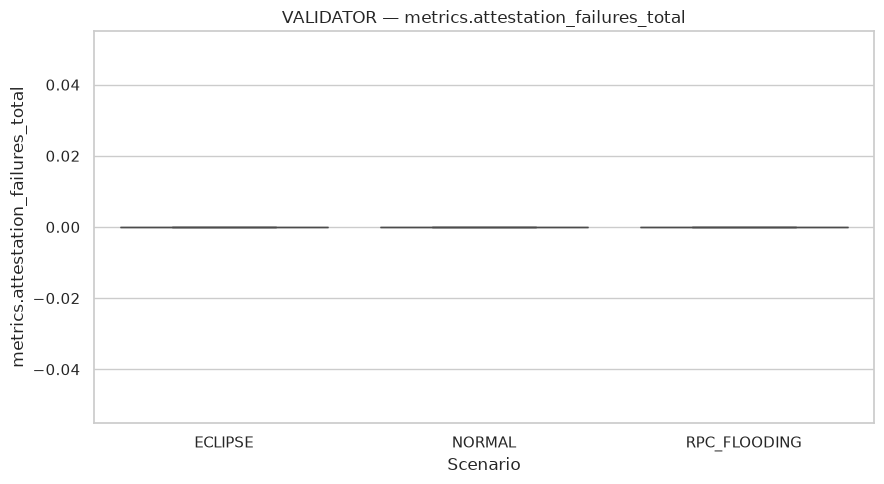

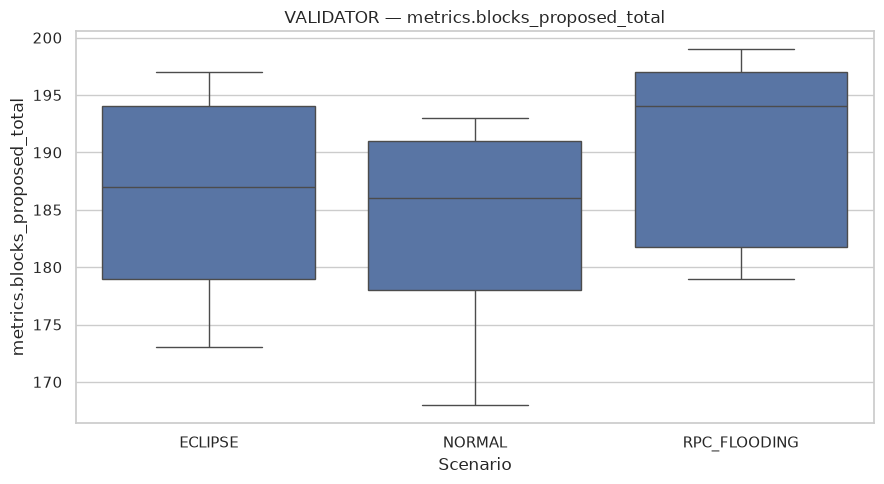

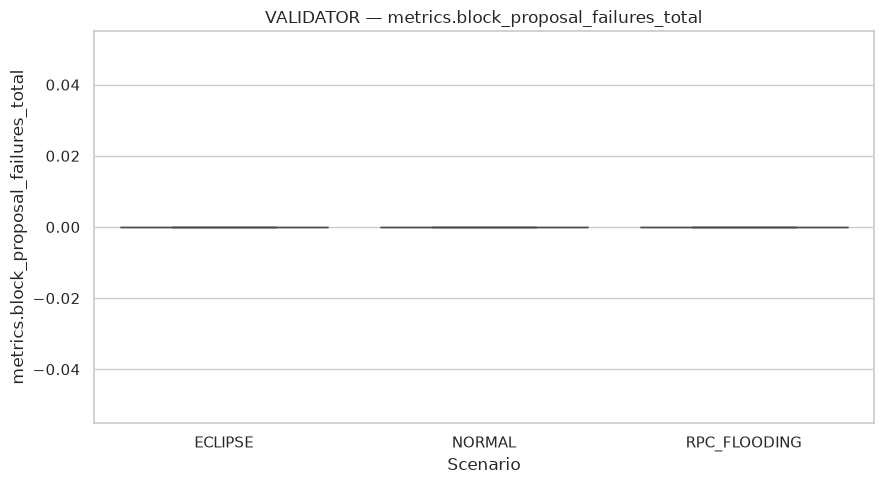

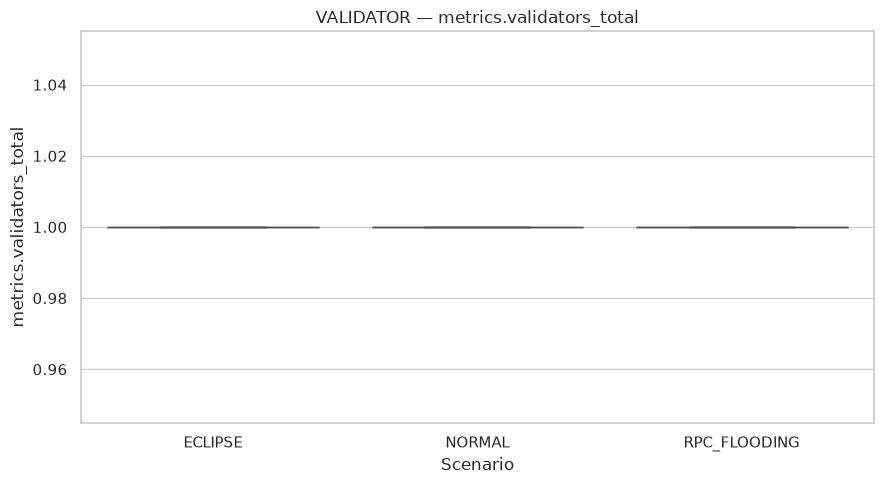

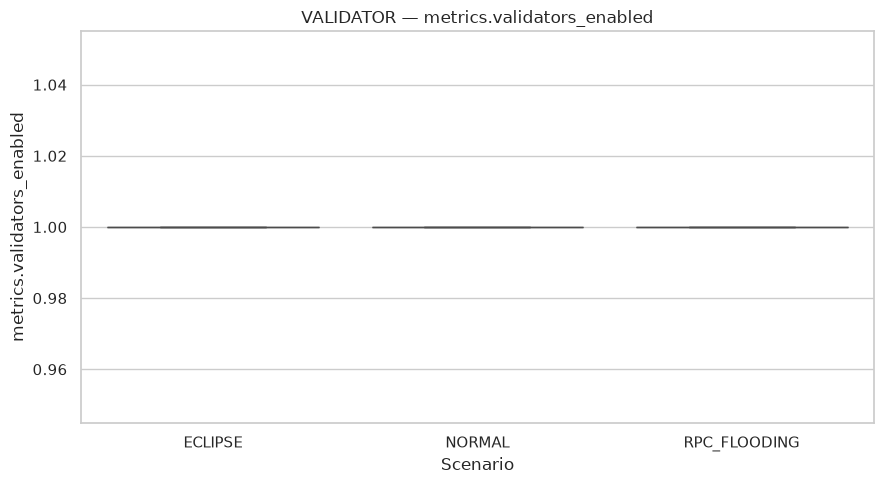

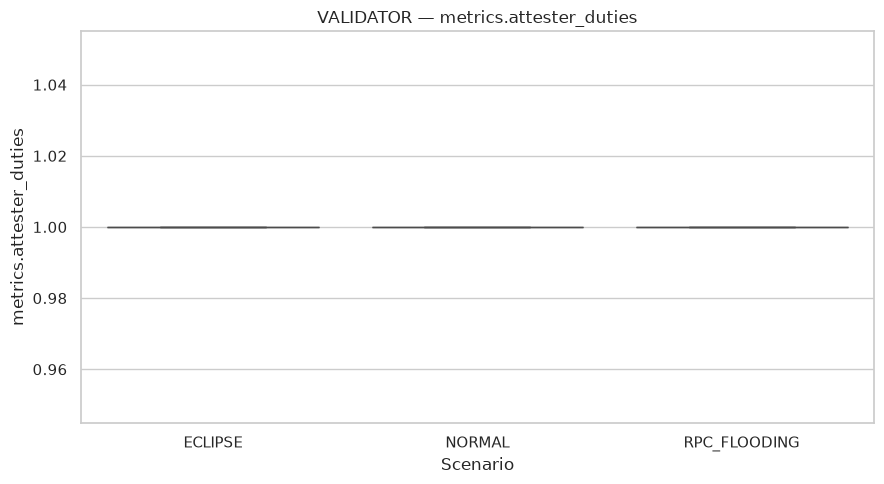

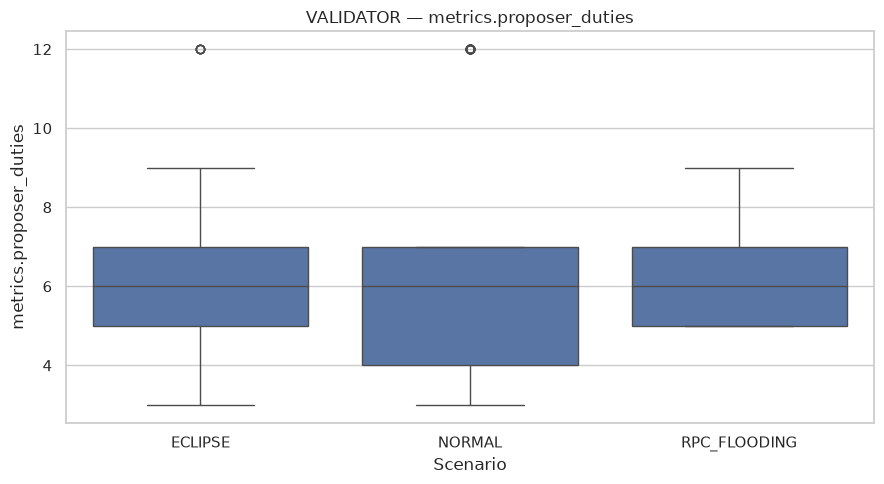

In [23]:
for component in sorted(flat_df["component"].dropna().unique()):

    component_data = flat_df[
        flat_df["component"] == component
    ]

    component_metrics = [
        col for col in numeric_columns
        if col.startswith("metrics.") or col.startswith("system.")
        if component_data[col].notna().sum() > 0
    ]

    for metric in component_metrics:

        plot_data = component_data[
            ["scenario", metric]
        ].dropna()

        if plot_data.empty:
            continue

        plt.figure(figsize=(9, 5))

        sns.boxplot(
            data=plot_data,
            x="scenario",
            y=metric
        )

        plt.title(f"{component.upper()} — {metric}")
        plt.xlabel("Scenario")
        plt.ylabel(metric)

        plt.tight_layout()

        safe_name = metric.replace(".", "_")

        plt.savefig(
            FIGURES_DIR / f"{component}_{safe_name}.png",
            dpi=150
        )

        plt.show()
        plt.close()

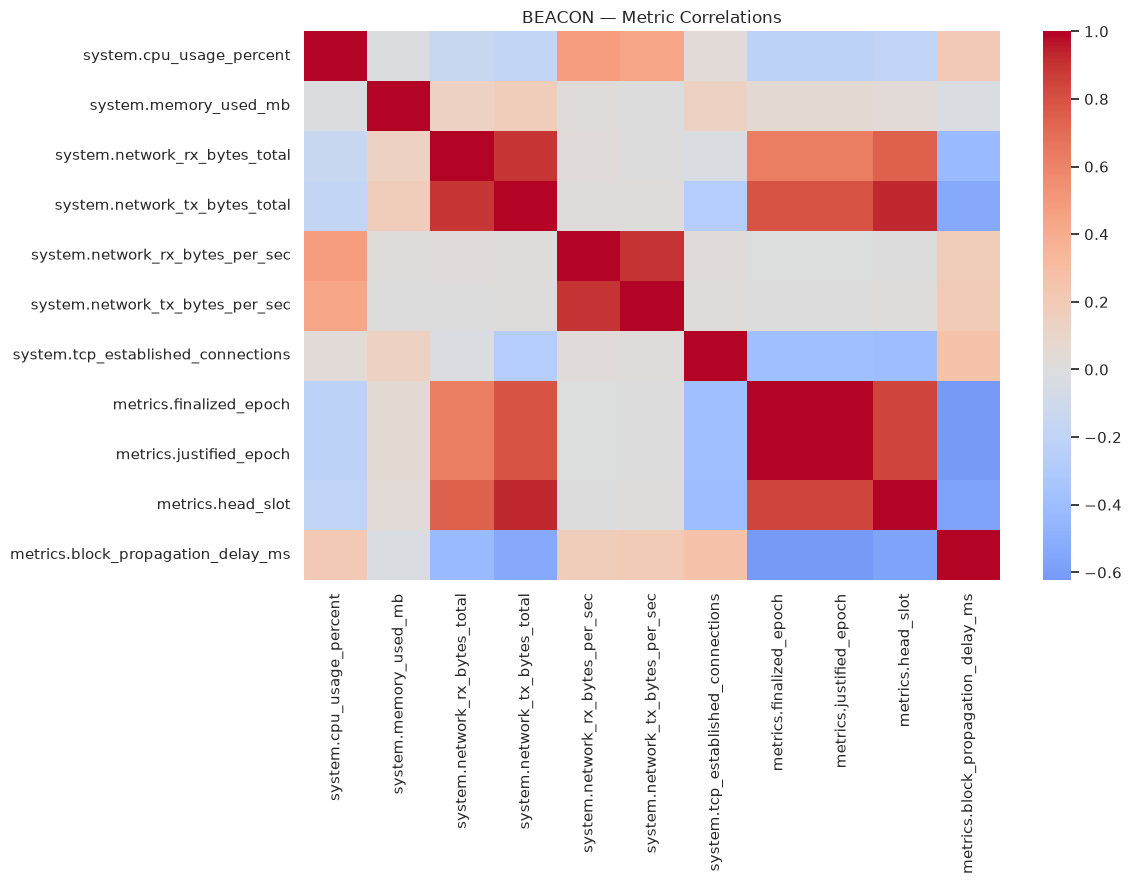

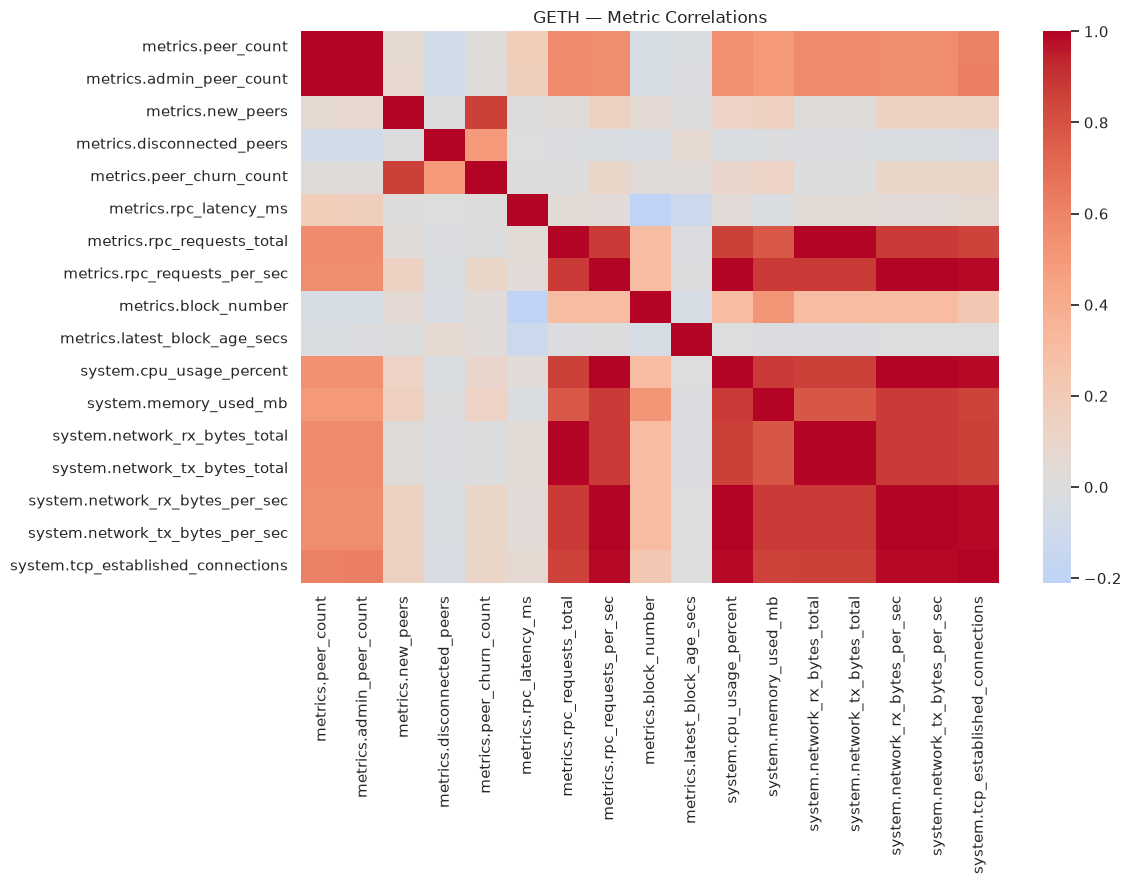

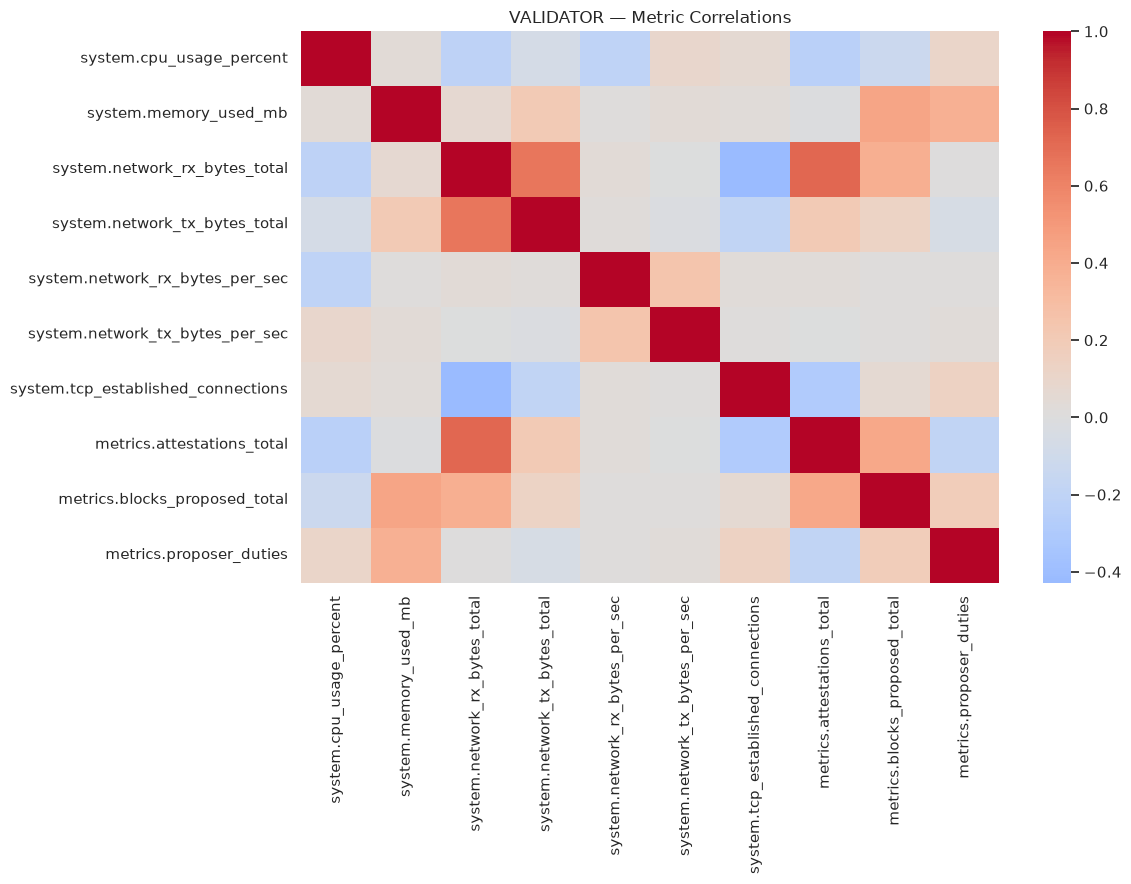

In [24]:
for component in sorted(flat_df["component"].dropna().unique()):

    component_data = flat_df[
        flat_df["component"] == component
    ]

    available_metrics = [
        col for col in numeric_columns
        if col.startswith("metrics.") or col.startswith("system.")
        if component_data[col].notna().sum() > 1
        and component_data[col].nunique(dropna=True) > 1
    ]

    if len(available_metrics) < 2:
        continue

    correlation = component_data[
        available_metrics
    ].corr()

    plt.figure(figsize=(12, 9))

    sns.heatmap(
        correlation,
        cmap="coolwarm",
        center=0,
        annot=False
    )

    plt.title(f"{component.upper()} — Metric Correlations")
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / f"{component}_correlation.png",
        dpi=150
    )

    plt.show()
    plt.close()

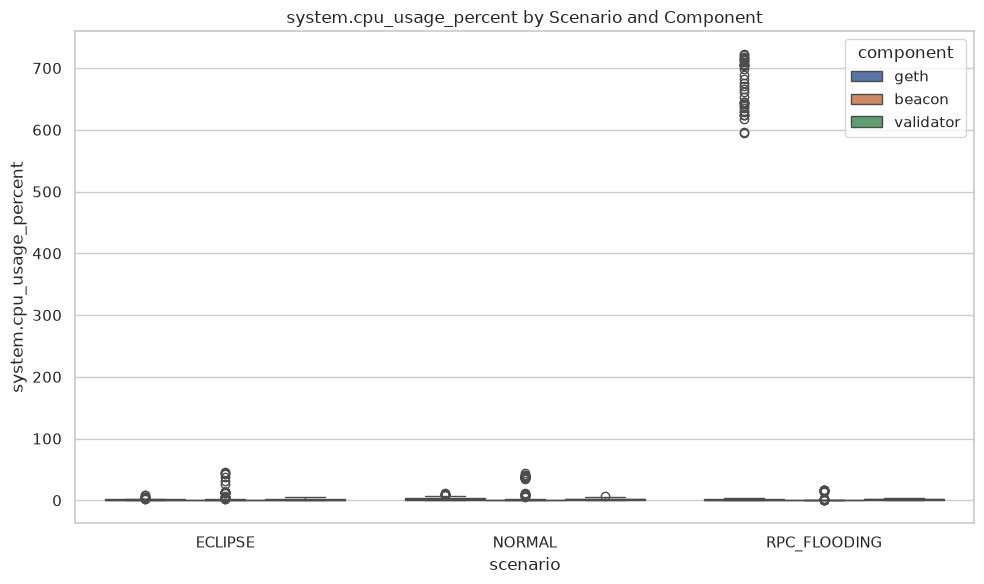

Metric not found: system.memory_usage_percent


In [25]:
system_metrics = [
    "system.cpu_usage_percent",
    "system.memory_usage_percent"
]

for metric in system_metrics:

    if metric not in flat_df.columns:
        print(f"Metric not found: {metric}")
        continue

    plot_data = flat_df[
        ["scenario", "component", metric]
    ].dropna()

    if plot_data.empty:
        continue

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=plot_data,
        x="scenario",
        y=metric,
        hue="component"
    )

    plt.title(f"{metric} by Scenario and Component")
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / f"{metric.replace('.', '_')}.png",
        dpi=150
    )

    plt.show()
    plt.close()

In [28]:
summary = {
    "total_observations": len(df),
    "total_columns": len(flat_df.columns),
    "scenarios": df["scenario"].nunique(),
    "components": df["component"].nunique(),
    "missing_cells": int(flat_df.isnull().sum().sum()),
    "exact_duplicates": int(exact_duplicates),
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["metric", "value"]
)

display(summary_df)

summary_df.to_csv(
    REPORT_DIR / "eda_summary.csv",
    index=False
)

missing_report.to_csv(
    REPORT_DIR / "missing_values.csv"
)

print("EDA reports saved to:", REPORT_DIR)
print("Figures saved to:", FIGURES_DIR)

,metric,value
0,total_observations,1620
1,total_columns,64
2,scenarios,3
3,components,3
4,missing_cells,58440
5,exact_duplicates,0


EDA reports saved to: /home/mohamed-amine/Downloads/EVA_ethereum/ml/reports/eda
Figures saved to: /home/mohamed-amine/Downloads/EVA_ethereum/ml/reports/eda/figures
